In [25]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/oneforyash/io-vnbd-dataset/.gitattributes
/kaggle/input/datasets/oneforyash/io-vnbd-dataset/README.md
/kaggle/input/datasets/oneforyash/io-vnbd-dataset/README_1.pdf
/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Synchronised V abd S datasets/Synchronised V abd S datasets/Categorised IOVNB Dataset/M (Driver B)/S-M.csv
/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Synchronised V abd S datasets/Synchronised V abd S datasets/Categorised IOVNB Dataset/M (Driver B)/V-M.JPG
/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Synchronised V abd S datasets/Synchronised V abd S datasets/Categorised IOVNB Dataset/M (Driver B)/V-M.csv
/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Synchronised V abd S datasets/Synchronised V abd S datasets/Categorised IOVNB Dataset/S (Driver A)/S1/S-S1.csv
/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Synchronised V abd S datasets/Synchronised V abd S datasets/Categorised IOVNB Dataset/S (Driver A)/S1/V-S1.JPG
/kaggle/input/datas

In [26]:
# preprocessing v2 (9 features: accel + gyro + magnetometer, glitch-masked heading)
# Self-contained replacement for imu_preprocessing.py. Run this cell, then rebuild your datasets:
#   train_ds, val_ds, test_ds, scaler = build_datasets(sensor_df, vehicle_df, time_offset_s=0.0)

import re
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset

# ---------------- column config ----------------
IMU_TIME_COL = "TIME SINCE START (ms)"
IMU_COLS = [
    "ACCELEROMETER X", "ACCELEROMETER Y", "ACCELEROMETER Z",
    "GYROSCOPE Yaw", "GYROSCOPE Pitch", "GYROSCOPE Roll",
    "MAGNETIC FIELD X", "MAGNETIC FIELD Y", "MAGNETIC FIELD Z",     # <- new
]
GT_TIME_COL = "Time Since Start of Day (seconds)"
VEL_COL = "Velocity (km/hr)"
HEAD_COL = "Heading (degrees)"

TICK_S = 0.1
WINDOW = 50

#  heading-label cleaning config 
GLITCH_DEG = 45.0       # label differs from its local (1.1 s) median heading by more than this -> glitch
ROLL_TICKS = 11
MIN_SPEED_KMH = 2.0     # GPS heading is unreliable when (nearly) stationary; set to 0 to disable


def standardize_mag_columns(df: pd.DataFrame) -> pd.DataFrame:
    """'MAGNETIC FIELD X (μT)' -> 'MAGNETIC FIELD X' (string matching, ignores unit suffix / spacing / case)."""
    rename = {}
    for c in df.columns:
        m = re.search(r"MAGNETIC\s*FIELD\s*([XYZ])", str(c), flags=re.I)
        if m:
            rename[c] = f"MAGNETIC FIELD {m.group(1).upper()}"
    return df.rename(columns=rename)


def circ_diff_deg(a, b):
    """Smallest absolute angular difference in degrees."""
    return np.abs((a - b + 180.0) % 360.0 - 180.0)


def flag_heading_glitches(heading_deg: pd.Series, speed_kmh: pd.Series) -> np.ndarray:
    """Returns boolean array: True where the heading label is trustworthy."""
    h = heading_deg.to_numpy(np.float64)
    r = np.deg2rad(h)
    s = pd.Series(np.sin(r)).rolling(ROLL_TICKS, center=True, min_periods=1).median()
    c = pd.Series(np.cos(r)).rolling(ROLL_TICKS, center=True, min_periods=1).median()
    ref = np.rad2deg(np.arctan2(s, c)) % 360.0

    bad = np.isnan(h)
    bad |= (h == 0.0)                                   # the "drops to exactly 0" hardware glitch
    bad |= circ_diff_deg(h, ref) > GLITCH_DEG           # any other spike vs. local median
    if MIN_SPEED_KMH > 0:
        bad |= speed_kmh.to_numpy(np.float64) < MIN_SPEED_KMH
    return ~bad


# downsample + merge 
def downsample_imu(sensor_df: pd.DataFrame) -> pd.DataFrame:
    t = sensor_df[IMU_TIME_COL].to_numpy(dtype=np.float64) / 1000.0
    df = sensor_df[IMU_COLS].copy()
    df.index = pd.to_timedelta(t, unit="s")
    df = df.sort_index()
    out = df.resample("100ms", label="right", closed="right").mean()
    out["tick"] = np.round(out.index.total_seconds() / TICK_S).astype(np.int64)
    return out.reset_index(drop=True)


def prepare_ground_truth(vehicle_df: pd.DataFrame, time_offset_s: float = 0.0) -> pd.DataFrame:
    t = vehicle_df[GT_TIME_COL].to_numpy(dtype=np.float64)
    t = t - t[0] - time_offset_s
    gt = vehicle_df[[VEL_COL, HEAD_COL]].copy()
    gt["tick"] = np.round(t / TICK_S).astype(np.int64)
    return gt.drop_duplicates("tick").reset_index(drop=True)


def merge_streams(sensor_df, vehicle_df, time_offset_s: float = 0.0) -> pd.DataFrame:
    sensor_df = standardize_mag_columns(sensor_df)
    imu10 = downsample_imu(sensor_df)
    gt = prepare_ground_truth(vehicle_df, time_offset_s)
    merged = imu10.merge(gt, on="tick", how="inner").sort_values("tick").reset_index(drop=True)

    # interpolate short gaps in IMU + velocity (NOT heading: linear interpolation across 359->0 is wrong)
    num_cols = IMU_COLS + [VEL_COL]
    merged[num_cols] = merged[num_cols].interpolate(limit=2, limit_area="inside")
    merged = merged.dropna(subset=num_cols).reset_index(drop=True)

    merged["heading_valid"] = flag_heading_glitches(merged[HEAD_COL], merged[VEL_COL])
    merged[HEAD_COL] = merged[HEAD_COL].ffill().bfill()          # placeholder values; masked out of the loss anyway
    merged["segment"] = (merged["tick"].diff().fillna(1) != 1).cumsum()

    print(f"Heading labels flagged as glitch/unreliable: {(~merged['heading_valid']).mean() * 100:.1f}% "
          f"({(~merged['heading_valid']).sum()} of {len(merged)} ticks)")
    return merged


#  scaler 
class StandardScaler:
    def fit(self, df):
        self.x_mean = df[IMU_COLS].mean().to_numpy(np.float32)
        self.x_std = df[IMU_COLS].std().replace(0, 1.0).to_numpy(np.float32)
        self.v_mean = float(df[VEL_COL].mean())
        self.v_std = float(df[VEL_COL].std() or 1.0)
        return self

    def transform_x(self, arr):
        return (arr - self.x_mean) / (self.x_std + 1e-8)

    def encode_y(self, vel, heading_deg):
        v = (vel - self.v_mean) / (self.v_std + 1e-8)
        h = np.deg2rad(heading_deg)
        return np.stack([v, np.sin(h), np.cos(h)], axis=-1).astype(np.float32)

    def decode_y(self, y):
        y = np.asarray(y)
        return y[..., 0] * self.v_std + self.v_mean, np.rad2deg(np.arctan2(y[..., 1], y[..., 2])) % 360.0


#  dataset (now also returns a heading-valid mask) 
class IMUWindowDataset(Dataset):
    """Item: X (50, 9), Y (3,), M (1,) where M=1 if the heading label at the last step is trustworthy."""

    def __init__(self, df, scaler, window=WINDOW, stride=1):
        self.window = window
        self.X = scaler.transform_x(df[IMU_COLS].to_numpy(np.float32)).astype(np.float32)
        self.Y = scaler.encode_y(df[VEL_COL].to_numpy(np.float64), df[HEAD_COL].to_numpy(np.float64))
        self.M = df["heading_valid"].to_numpy(np.float32)

        seg = df["segment"].to_numpy()
        starts = []
        for s in np.unique(seg):
            idx = np.flatnonzero(seg == s)
            starts.extend(range(idx[0], idx[-1] - window + 2, stride))
        self.starts = np.asarray(starts, dtype=np.int64)

    def __len__(self):
        return len(self.starts)

    def __getitem__(self, i):
        s = self.starts[i]
        e = s + self.window
        return (torch.from_numpy(self.X[s:e]),
                torch.from_numpy(self.Y[e - 1]),
                torch.tensor([self.M[e - 1]]))


def build_datasets(sensor_df, vehicle_df, time_offset_s=0.0,
                   train_frac=0.7, val_frac=0.15, window=WINDOW, stride=1):
    merged = merge_streams(sensor_df, vehicle_df, time_offset_s)
    n = len(merged)
    i1, i2 = int(n * train_frac), int(n * (train_frac + val_frac))
    train_df, val_df, test_df = merged.iloc[:i1], merged.iloc[i1:i2], merged.iloc[i2:]
    scaler = StandardScaler().fit(train_df)
    mk = lambda d, st: IMUWindowDataset(d, scaler, window, st)
    return mk(train_df, stride), mk(val_df, 1), mk(test_df, 1), scaler

In [27]:
import os

print("Searching for the S1 files...")
for root, dirs, files in os.walk('/kaggle/input/'):
    for file in files:
        if 'S-S1.csv' in file or 'V-S1.csv' in file:
            print(os.path.join(root, file))

Searching for the S1 files...
/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Synchronised V abd S datasets/Synchronised V abd S datasets/Categorised IOVNB Dataset/S (Driver A)/S1/S-S1.csv
/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Synchronised V abd S datasets/Synchronised V abd S datasets/Categorised IOVNB Dataset/S (Driver A)/S1/V-S1.csv
/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Synchronised V abd S datasets/Synchronised V abd S datasets/Uncategorised IOVNB Dataset/S-Dataset/S-S1.csv
/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Synchronised V abd S datasets/Synchronised V abd S datasets/Uncategorised IOVNB Dataset/V-Dataset/V-S1.csv
/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Unsynchronised V and S Dataset/Unsynchronised V and S Dataset/Categorised IOVNB (V) Dataset/V Dataset/S (Driver A)/S1/V-S1.csv
/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Unsynchronised V and S Dataset/Unsynchronised V and S Dataset/Uncategorised IOVNB (V and S) Dataset/S-Datas

In [28]:
import pandas as pd

# 1. Paths for Driver A, S1 route
sensor_path = '/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Synchronised V abd S datasets/Synchronised V abd S datasets/Categorised IOVNB Dataset/S (Driver A)/S1/S-S1.csv'
vehicle_path = '/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Synchronised V abd S datasets/Synchronised V abd S datasets/Categorised IOVNB Dataset/S (Driver A)/S1/V-S1.csv'

# 2. Load data
sensor_df = pd.read_csv(sensor_path, encoding='latin1')
vehicle_df = pd.read_csv(vehicle_path)

# 3. Clean column names
sensor_df.columns = sensor_df.columns.str.strip()
vehicle_df.columns = vehicle_df.columns.str.strip()

# 4. Rename columns (including the new Magnetometer features)
rename_dict = {}
for col in sensor_df.columns:
    if 'ACCELEROMETER X' in col: rename_dict[col] = 'ACCELEROMETER X'
    elif 'ACCELEROMETER Y' in col: rename_dict[col] = 'ACCELEROMETER Y'
    elif 'ACCELEROMETER Z' in col: rename_dict[col] = 'ACCELEROMETER Z'
    elif 'GYROSCOPE Yaw' in col: rename_dict[col] = 'GYROSCOPE Yaw'
    elif 'GYROSCOPE Pitch' in col: rename_dict[col] = 'GYROSCOPE Pitch'
    elif 'GYROSCOPE Roll' in col: rename_dict[col] = 'GYROSCOPE Roll'
    # Adding Magnetometer
    elif 'MAGNETIC FIELD X' in col: rename_dict[col] = 'MAGNETIC FIELD X'
    elif 'MAGNETIC FIELD Y' in col: rename_dict[col] = 'MAGNETIC FIELD Y'
    elif 'MAGNETIC FIELD Z' in col: rename_dict[col] = 'MAGNETIC FIELD Z'

sensor_df = sensor_df.rename(columns=rename_dict)

print("S1 Data loaded successfully! Ready for preprocessing.")

S1 Data loaded successfully! Ready for preprocessing.


In [29]:
from torch.utils.data import DataLoader

# This will trigger the function, process the data, and print the glitch percentage!
train_ds, val_ds, test_ds, scaler = build_datasets(sensor_df, vehicle_df, time_offset_s=0.0)

train_dl = DataLoader(train_ds, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)
val_dl = DataLoader(val_ds, batch_size=128, shuffle=False, num_workers=2, pin_memory=True)
test_dl = DataLoader(test_ds, batch_size=128, shuffle=False, num_workers=2, pin_memory=True)

print("DataLoaders rebuilt successfully with masks!")

Heading labels flagged as glitch/unreliable: 11.3% (5839 of 51717 ticks)
DataLoaders rebuilt successfully with masks!


In [30]:
# ---- Kaggle cell: TCN+GRU (9 features) with masked angular heading loss ----
# Assumes train_dl / val_dl / test_dl are built from preprocessing_v2 (batches are (X, Y, M)) and `scaler` exists.
import copy
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)


class CausalConv1d(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size, dilation):
        super().__init__()
        self.pad = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(in_ch, out_ch, kernel_size, dilation=dilation)

    def forward(self, x):
        return self.conv(F.pad(x, (self.pad, 0)))


class TCNBlock(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size, dilation, dropout):
        super().__init__()
        self.conv1 = CausalConv1d(in_ch, out_ch, kernel_size, dilation)
        self.conv2 = CausalConv1d(out_ch, out_ch, kernel_size, dilation)
        self.norm1 = nn.GroupNorm(1, out_ch)
        self.norm2 = nn.GroupNorm(1, out_ch)
        self.drop = nn.Dropout(dropout)
        self.res = nn.Conv1d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x):
        out = self.drop(F.relu(self.norm1(self.conv1(x))))
        out = self.drop(F.relu(self.norm2(self.conv2(out))))
        return F.relu(out + self.res(x))


class TCN_GRU(nn.Module):
    def __init__(self, in_features=9, tcn_channels=64, kernel_size=3,
                 dilations=(1, 2, 4, 8), gru_hidden=64, gru_layers=2,
                 dropout=0.2, out_features=3):
        super().__init__()
        blocks, ch = [], in_features
        for d in dilations:
            blocks.append(TCNBlock(ch, tcn_channels, kernel_size, d, dropout))
            ch = tcn_channels
        self.tcn = nn.Sequential(*blocks)
        self.gru = nn.GRU(tcn_channels, gru_hidden, num_layers=gru_layers,
                          batch_first=True, dropout=dropout if gru_layers > 1 else 0.0)
        self.fc = nn.Linear(gru_hidden, out_features)

    def forward(self, x):                      # (B, 50, 9)
        x = self.tcn(x.transpose(1, 2)).transpose(1, 2)
        out, _ = self.gru(x)
        return self.fc(out[:, -1])


# ---------------- loss ----------------
VEL_WEIGHT = 1.0
HEAD_WEIGHT = 2.0       # tune in [1, 5]
NORM_REG = 0.1          # keeps (sin, cos) prediction near unit length

huber = nn.HuberLoss(reduction='mean')


def multitask_loss(pred, y, m):
    """pred, y: (B,3) = [vel_norm, sin, cos]; m: (B,1) heading-valid mask."""
    m = m.squeeze(1)
    vel_loss = huber(pred[:, 0], y[:, 0])                          # velocity labels are trusted

    sc = pred[:, 1:]
    norm = sc.norm(dim=1).clamp(min=1e-6)
    cos_sim = ((sc / norm.unsqueeze(1)) * y[:, 1:]).sum(dim=1)     # cos(angle error)
    ang = 1.0 - cos_sim                                            # 0 = perfect, 2 = opposite
    denom = m.sum().clamp(min=1.0)
    head_loss = (ang * m).sum() / denom                            # glitch labels contribute nothing
    reg = (((norm - 1.0) ** 2) * m).sum() / denom

    return VEL_WEIGHT * vel_loss + HEAD_WEIGHT * head_loss + NORM_REG * reg, vel_loss, head_loss


@torch.no_grad()
def metrics(loader, model):
    """Speed MAE (km/h), heading MAE on trusted labels, heading MAE on ALL labels (comparable to your old 92.5)."""
    model.eval()
    v_err, h_err_all, h_err_clean, n, n_clean = 0.0, 0.0, 0.0, 0, 0
    for x, y, m in loader:
        x, y, m = x.to(device), y.to(device), m.to(device).squeeze(1)
        p = model(x)
        v_err += ((p[:, 0] - y[:, 0]).abs() * scaler.v_std).sum().item()
        ang_p = torch.rad2deg(torch.atan2(p[:, 1], p[:, 2]))
        ang_t = torch.rad2deg(torch.atan2(y[:, 1], y[:, 2]))
        d = ((ang_p - ang_t + 180.0) % 360.0 - 180.0).abs()
        h_err_all += d.sum().item()
        h_err_clean += (d * m).sum().item()
        n += x.size(0)
        n_clean += m.sum().item()
    return v_err / n, h_err_clean / max(n_clean, 1), h_err_all / n


# ---------------- training ----------------
model = TCN_GRU(in_features=9).to(device)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

EPOCHS = 20
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)


def run_epoch(loader, train):
    model.train(train)
    tot, n = 0.0, 0
    with torch.set_grad_enabled(train):
        for x, y, m in loader:
            x, y, m = x.to(device, non_blocking=True), y.to(device), m.to(device)
            loss, _, _ = multitask_loss(model(x), y, m)
            if train:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            tot += loss.item() * x.size(0)
            n += x.size(0)
    return tot / n


best_val, best_state = float('inf'), None
for epoch in range(1, EPOCHS + 1):
    tr = run_epoch(train_dl, True)
    va = run_epoch(val_dl, False)
    v_mae, h_clean, h_all = metrics(val_dl, model)
    flag = ""
    if va < best_val:
        best_val, best_state = va, copy.deepcopy(model.state_dict())
        torch.save(best_state, "best_tcn_gru_v2.pt")
        flag = " <- best"
    print(f"Epoch {epoch:02d}/{EPOCHS} | Train {tr:.4f} | Val {va:.4f} | "
          f"Val speed MAE {v_mae:.2f} km/h | heading MAE clean {h_clean:.1f}° / all {h_all:.1f}°{flag}")

model.load_state_dict(best_state)
v_mae, h_clean, h_all = metrics(test_dl, model)       # test_dl: your test DataLoader
print(f"\nTEST | speed MAE {v_mae:.2f} km/h | heading MAE clean {h_clean:.1f}° | heading MAE all-labels {h_all:.1f}°")

Using device: cuda
Trainable parameters: 140,035
Epoch 01/20 | Train 0.4173 | Val 0.4459 | Val speed MAE 10.18 km/h | heading MAE clean 15.1° / all 15.2° <- best
Epoch 02/20 | Train 0.2130 | Val 0.3310 | Val speed MAE 7.52 km/h | heading MAE clean 14.9° / all 16.6° <- best
Epoch 03/20 | Train 0.1496 | Val 0.3726 | Val speed MAE 7.66 km/h | heading MAE clean 16.6° / all 17.5°
Epoch 04/20 | Train 0.1112 | Val 0.4269 | Val speed MAE 7.73 km/h | heading MAE clean 20.1° / all 21.5°
Epoch 05/20 | Train 0.0900 | Val 0.4597 | Val speed MAE 7.85 km/h | heading MAE clean 21.4° / all 22.4°
Epoch 06/20 | Train 0.0732 | Val 0.3843 | Val speed MAE 7.49 km/h | heading MAE clean 18.3° / all 19.7°
Epoch 07/20 | Train 0.0627 | Val 0.3887 | Val speed MAE 7.77 km/h | heading MAE clean 17.6° / all 18.9°
Epoch 08/20 | Train 0.0567 | Val 0.4060 | Val speed MAE 8.03 km/h | heading MAE clean 18.6° / all 19.1°
Epoch 09/20 | Train 0.0441 | Val 0.4456 | Val speed MAE 8.31 km/h | heading MAE clean 19.8° / all 21.3

In [31]:
# dataset v3 (noise augmentation). Run AFTER the preprocessing_v2 cell; it overrides these two names.
# Then rebuild:
#   train_ds, val_ds, test_ds, scaler = build_datasets(sensor_df, vehicle_df, time_offset_s=0.0)
#   train_dl = DataLoader(train_ds, batch_size=128, shuffle=True,  num_workers=2, pin_memory=True)
#   val_dl   = DataLoader(val_ds,   batch_size=256, shuffle=False, num_workers=2, pin_memory=True)
#   test_dl  = DataLoader(test_ds,  batch_size=256, shuffle=False, num_workers=2, pin_memory=True)

import numpy as np
import torch
from torch.utils.data import Dataset

NOISE_STD = 0.05      # in normalized (z-score) units; try 0.02 - 0.10


class IMUWindowDataset(Dataset):
    """Item: X (50, 9), Y (3,), M (1,). Gaussian jitter is added to X only when augment=True (train split)."""

    def __init__(self, df, scaler, window=WINDOW, stride=1, augment=False, noise_std=NOISE_STD):
        self.window = window
        self.augment = augment
        self.noise_std = noise_std
        self.X = scaler.transform_x(df[IMU_COLS].to_numpy(np.float32)).astype(np.float32)
        self.Y = scaler.encode_y(df[VEL_COL].to_numpy(np.float64), df[HEAD_COL].to_numpy(np.float64))
        self.M = df["heading_valid"].to_numpy(np.float32)

        seg = df["segment"].to_numpy()
        starts = []
        for s in np.unique(seg):
            idx = np.flatnonzero(seg == s)
            starts.extend(range(idx[0], idx[-1] - window + 2, stride))
        self.starts = np.asarray(starts, dtype=np.int64)

    def __len__(self):
        return len(self.starts)

    def __getitem__(self, i):
        s = self.starts[i]
        e = s + self.window
        x = torch.from_numpy(self.X[s:e]).clone()
        if self.augment and self.noise_std > 0:
            x = x + torch.randn_like(x) * self.noise_std      # fresh noise every time the sample is drawn
        return x, torch.from_numpy(self.Y[e - 1]), torch.tensor([self.M[e - 1]])


def build_datasets(sensor_df, vehicle_df, time_offset_s=0.0,
                   train_frac=0.7, val_frac=0.15, window=WINDOW, stride=1, noise_std=NOISE_STD):
    merged = merge_streams(sensor_df, vehicle_df, time_offset_s)
    n = len(merged)
    i1, i2 = int(n * train_frac), int(n * (train_frac + val_frac))
    train_df, val_df, test_df = merged.iloc[:i1], merged.iloc[i1:i2], merged.iloc[i2:]
    scaler = StandardScaler().fit(train_df)
    train_ds = IMUWindowDataset(train_df, scaler, window, stride, augment=True, noise_std=noise_std)
    val_ds = IMUWindowDataset(val_df, scaler, window, 1, augment=False)
    test_ds = IMUWindowDataset(test_df, scaler, window, 1, augment=False)
    return train_ds, val_ds, test_ds, scaler

In [32]:
train_ds, val_ds, test_ds, scaler = build_datasets(sensor_df, vehicle_df, time_offset_s=0.0)
print("Datasets rebuilt with augmentation!")

Heading labels flagged as glitch/unreliable: 11.3% (5839 of 51717 ticks)
Datasets rebuilt with augmentation!


In [33]:
from torch.utils.data import DataLoader

train_dl = DataLoader(train_ds, batch_size=128, shuffle=True,  num_workers=2, pin_memory=True)
val_dl   = DataLoader(val_ds,   batch_size=256, shuffle=False, num_workers=2, pin_memory=True)
test_dl  = DataLoader(test_ds,  batch_size=256, shuffle=False, num_workers=2, pin_memory=True)
print("DataLoaders rebuilt!")

DataLoaders rebuilt!


In [34]:
#Kaggle cell: TCN + Causal Transformer, AdamW + CosineAnnealingWarmRestarts, balanced loss
# Assumes train_dl / val_dl / test_dl (batches are (X, Y, M)) and `scaler` exist (see dataset_v3 cell).
import copy
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)


# TCN (unchanged, causal) 
class CausalConv1d(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size, dilation):
        super().__init__()
        self.pad = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(in_ch, out_ch, kernel_size, dilation=dilation)

    def forward(self, x):
        return self.conv(F.pad(x, (self.pad, 0)))


class TCNBlock(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size, dilation, dropout):
        super().__init__()
        self.conv1 = CausalConv1d(in_ch, out_ch, kernel_size, dilation)
        self.conv2 = CausalConv1d(out_ch, out_ch, kernel_size, dilation)
        self.norm1 = nn.GroupNorm(1, out_ch)
        self.norm2 = nn.GroupNorm(1, out_ch)
        self.drop = nn.Dropout(dropout)
        self.res = nn.Conv1d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x):
        out = self.drop(F.relu(self.norm1(self.conv1(x))))
        out = self.drop(F.relu(self.norm2(self.conv2(out))))
        return F.relu(out + self.res(x))


# positional encoding + causal transformer 
class SinusoidalPE(nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pos = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))        # (1, max_len, d_model)

    def forward(self, x):                                  # x: (B, T, d_model)
        return x + self.pe[:, : x.size(1)]


class TCN_Transformer(nn.Module):
    def __init__(self, in_features=9, d_model=64, kernel_size=3, dilations=(1, 2, 4, 8),
                 n_heads=4, n_layers=2, dim_ff=128, dropout=0.2, out_features=3, window=50):
        super().__init__()
        blocks, ch = [], in_features
        for d in dilations:
            blocks.append(TCNBlock(ch, d_model, kernel_size, d, dropout))
            ch = d_model
        self.tcn = nn.Sequential(*blocks)                  # (B, 9, T) -> (B, d_model, T)

        # Positional encoding is added AFTER the TCN projects 9 -> d_model: 9 channels can't be split
        # across attention heads, and the transformer should see position in its own feature space.
        self.pos = SinusoidalPE(d_model, max_len=window)
        layer = nn.TransformerEncoderLayer(d_model, n_heads, dim_ff, dropout,
                                           batch_first=True, norm_first=True, activation="gelu")
        self.encoder = nn.TransformerEncoder(layer, n_layers, norm=nn.LayerNorm(d_model),
                                             enable_nested_tensor=False)
        # True above the diagonal = "may not attend": step t only sees steps <= t
        self.register_buffer("causal_mask", torch.triu(torch.ones(window, window, dtype=torch.bool), diagonal=1))
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(d_model, out_features))

    def forward(self, x):                                  # (B, 50, 9)
        x = self.tcn(x.transpose(1, 2)).transpose(1, 2)    # (B, 50, d_model)
        x = self.pos(x)
        T = x.size(1)
        x = self.encoder(x, mask=self.causal_mask[:T, :T])
        return self.head(x[:, -1])                         # last timestep -> (B, 3)


# loss (balanced) 
VEL_WEIGHT = 1.0
HEAD_WEIGHT = 1.0
NORM_REG = 0.1
huber = nn.HuberLoss(reduction='mean')


def multitask_loss(pred, y, m):
    m = m.squeeze(1)
    vel_loss = huber(pred[:, 0], y[:, 0])
    sc = pred[:, 1:]
    norm = sc.norm(dim=1).clamp(min=1e-6)
    ang = 1.0 - ((sc / norm.unsqueeze(1)) * y[:, 1:]).sum(dim=1)
    denom = m.sum().clamp(min=1.0)
    head_loss = (ang * m).sum() / denom
    reg = (((norm - 1.0) ** 2) * m).sum() / denom
    return VEL_WEIGHT * vel_loss + HEAD_WEIGHT * head_loss + NORM_REG * reg


@torch.no_grad()
def metrics(loader, model):
    model.eval()
    v_err, h_clean, h_all, n, n_clean = 0.0, 0.0, 0.0, 0, 0
    for x, y, m in loader:
        x, y, m = x.to(device), y.to(device), m.to(device).squeeze(1)
        p = model(x)
        v_err += ((p[:, 0] - y[:, 0]).abs() * scaler.v_std).sum().item()
        ap = torch.rad2deg(torch.atan2(p[:, 1], p[:, 2]))
        at = torch.rad2deg(torch.atan2(y[:, 1], y[:, 2]))
        d = ((ap - at + 180.0) % 360.0 - 180.0).abs()
        h_all += d.sum().item()
        h_clean += (d * m).sum().item()
        n += x.size(0)
        n_clean += m.sum().item()
    return v_err / n, h_clean / max(n_clean, 1), h_all / n


# training 
model = TCN_Transformer(in_features=9).to(device)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

EPOCHS = 20
PATIENCE = 6                                               # early stopping on val loss
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.05)
# T_0=5, T_mult=1 -> restarts at epochs 5, 10, 15; the 20-epoch run ends exactly at the bottom of a cycle
scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=5, T_mult=1, eta_min=1e-6)


def run_epoch(loader, train, epoch=0):
    model.train(train)
    tot, n = 0.0, 0
    iters = len(loader)
    with torch.set_grad_enabled(train):
        for i, (x, y, m) in enumerate(loader):
            x, y, m = x.to(device, non_blocking=True), y.to(device), m.to(device)
            loss = multitask_loss(model(x), y, m)
            if train:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                scheduler.step(epoch + i / iters)          # smooth per-batch cosine schedule
            tot += loss.item() * x.size(0)
            n += x.size(0)
    return tot / n


best_val, best_state, bad = float('inf'), None, 0
for epoch in range(EPOCHS):
    tr = run_epoch(train_dl, True, epoch)
    va = run_epoch(val_dl, False)
    v_mae, h_clean, h_all = metrics(val_dl, model)
    flag = ""
    if va < best_val:
        best_val, best_state, bad = va, copy.deepcopy(model.state_dict()), 0
        torch.save(best_state, "best_tcn_transformer_v3.pt")
        flag = " <- best"
    else:
        bad += 1
    print(f"Epoch {epoch + 1:02d}/{EPOCHS} | lr {optimizer.param_groups[0]['lr']:.2e} | Train {tr:.4f} | Val {va:.4f} | "
          f"Val speed MAE {v_mae:.2f} km/h | heading MAE clean {h_clean:.1f}° / all {h_all:.1f}°{flag}")
    if bad >= PATIENCE:
        print(f"Early stopping: no val improvement for {PATIENCE} epochs.")
        break

model.load_state_dict(best_state)
v_mae, h_clean, h_all = metrics(test_dl, model)
print(f"\nTEST | speed MAE {v_mae:.2f} km/h | heading MAE clean {h_clean:.1f}° | heading MAE all-labels {h_all:.1f}°")

Using device: cuda
Trainable parameters: 157,187
Epoch 01/20 | lr 9.05e-04 | Train 0.3533 | Val 0.4033 | Val speed MAE 10.37 km/h | heading MAE clean 18.2° / all 19.8° <- best
Epoch 02/20 | lr 6.56e-04 | Train 0.1889 | Val 0.2669 | Val speed MAE 7.57 km/h | heading MAE clean 14.9° / all 16.5° <- best
Epoch 03/20 | lr 3.47e-04 | Train 0.1514 | Val 0.3422 | Val speed MAE 8.43 km/h | heading MAE clean 18.0° / all 23.6°
Epoch 04/20 | lr 9.70e-05 | Train 0.1265 | Val 0.3166 | Val speed MAE 8.28 km/h | heading MAE clean 17.0° / all 19.5°
Epoch 05/20 | lr 1.00e-06 | Train 0.1154 | Val 0.3069 | Val speed MAE 8.12 km/h | heading MAE clean 16.7° / all 19.5°
Epoch 06/20 | lr 9.05e-04 | Train 0.1290 | Val 0.3872 | Val speed MAE 8.84 km/h | heading MAE clean 22.6° / all 23.8°
Epoch 07/20 | lr 6.56e-04 | Train 0.1004 | Val 0.3238 | Val speed MAE 8.29 km/h | heading MAE clean 17.9° / all 20.0°
Epoch 08/20 | lr 3.47e-04 | Train 0.0811 | Val 0.3315 | Val speed MAE 8.54 km/h | heading MAE clean 16.9° / 

In [35]:
import pandas as pd
import numpy as np

def load_and_rename(sensor_path, vehicle_path):
    s_df = pd.read_csv(sensor_path, encoding='latin1')
    v_df = pd.read_csv(vehicle_path)
    s_df.columns = s_df.columns.str.strip()
    v_df.columns = v_df.columns.str.strip()
    
    rename_dict = {}
    for col in s_df.columns:
        if 'ACCELEROMETER X' in col: rename_dict[col] = 'ACCELEROMETER X'
        elif 'ACCELEROMETER Y' in col: rename_dict[col] = 'ACCELEROMETER Y'
        elif 'ACCELEROMETER Z' in col: rename_dict[col] = 'ACCELEROMETER Z'
        elif 'GYROSCOPE Yaw' in col: rename_dict[col] = 'GYROSCOPE Yaw'
        elif 'GYROSCOPE Pitch' in col: rename_dict[col] = 'GYROSCOPE Pitch'
        elif 'GYROSCOPE Roll' in col: rename_dict[col] = 'GYROSCOPE Roll'
        elif 'MAGNETIC FIELD X' in col: rename_dict[col] = 'MAGNETIC FIELD X'
        elif 'MAGNETIC FIELD Y' in col: rename_dict[col] = 'MAGNETIC FIELD Y'
        elif 'MAGNETIC FIELD Z' in col: rename_dict[col] = 'MAGNETIC FIELD Z'
    
    return s_df.rename(columns=rename_dict), v_df

# Base path
base = '/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Synchronised V abd S datasets/Synchronised V abd S datasets/Categorised IOVNB Dataset/'

# 1. Driver B (Motorway)
s_m, v_m = load_and_rename(f'{base}M (Driver B)/S-M.csv', f'{base}M (Driver B)/V-M.csv')

# 2. Driver A (Suburban S1)
s_s1, v_s1 = load_and_rename(f'{base}S (Driver A)/S1/S-S1.csv', f'{base}S (Driver A)/S1/V-S1.csv')

# 3. Driver E (Vw01 - Urban/Winding)
s_vw, v_vw = load_and_rename(f'{base}Vw (Driver E)/Vw01/S-Vw1.csv', f'{base}Vw (Driver E)/Vw01/V-Vw1.csv')

# COMBINE AND OFFSET TIMESTAMPS
# We must add an offset so the timelines don't overlap when combined

# Driver B starts at 0
sensor_df = s_m.copy()
vehicle_df = v_m.copy()

# Driver A offset (Add 1 hour to keep it strictly after Driver B)
s_s1['TIME SINCE START (ms)'] += sensor_df['TIME SINCE START (ms)'].max() + 10000
v_s1['Time Since Start of Day (seconds)'] += vehicle_df['Time Since Start of Day (seconds)'].max() + 10
sensor_df = pd.concat([sensor_df, s_s1], ignore_index=True)
vehicle_df = pd.concat([vehicle_df, v_s1], ignore_index=True)

# Driver E offset (Add another hour)
s_vw['TIME SINCE START (ms)'] += sensor_df['TIME SINCE START (ms)'].max() + 10000
v_vw['Time Since Start of Day (seconds)'] += vehicle_df['Time Since Start of Day (seconds)'].max() + 10
sensor_df = pd.concat([sensor_df, s_vw], ignore_index=True)
vehicle_df = pd.concat([vehicle_df, v_vw], ignore_index=True)

print(f"Combined Dataset Loaded! Total IMU rows: {len(sensor_df):,}")

Combined Dataset Loaded! Total IMU rows: 178,196


In [36]:
# Rebuild datasets (This will now apply the 11.3% glitch mask to ALL 3 drives combined)
train_ds, val_ds, test_ds, scaler = build_datasets(sensor_df, vehicle_df, time_offset_s=0.0)

from torch.utils.data import DataLoader
train_dl = DataLoader(train_ds, batch_size=128, shuffle=True,  num_workers=2, pin_memory=True)
val_dl   = DataLoader(val_ds,   batch_size=256, shuffle=False, num_workers=2, pin_memory=True)
test_dl  = DataLoader(test_ds,  batch_size=256, shuffle=False, num_workers=2, pin_memory=True)
print("Multi-Driver DataLoaders Ready!")

Heading labels flagged as glitch/unreliable: 10.6% (11167 of 105847 ticks)
Multi-Driver DataLoaders Ready!


In [37]:
import pandas as pd

# Paths for Driver B
sensor_path = '/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Synchronised V abd S datasets/Synchronised V abd S datasets/Categorised IOVNB Dataset/M (Driver B)/S-M.csv'
vehicle_path = '/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Synchronised V abd S datasets/Synchronised V abd S datasets/Categorised IOVNB Dataset/M (Driver B)/V-M.csv'

sensor_df = pd.read_csv(sensor_path, encoding='latin1')
vehicle_df = pd.read_csv(vehicle_path)

sensor_df.columns = sensor_df.columns.str.strip()
vehicle_df.columns = vehicle_df.columns.str.strip()

rename_dict = {}
for col in sensor_df.columns:
    if 'ACCELEROMETER X' in col: rename_dict[col] = 'ACCELEROMETER X'
    elif 'ACCELEROMETER Y' in col: rename_dict[col] = 'ACCELEROMETER Y'
    elif 'ACCELEROMETER Z' in col: rename_dict[col] = 'ACCELEROMETER Z'
    elif 'GYROSCOPE Yaw' in col: rename_dict[col] = 'GYROSCOPE Yaw'
    elif 'GYROSCOPE Pitch' in col: rename_dict[col] = 'GYROSCOPE Pitch'
    elif 'GYROSCOPE Roll' in col: rename_dict[col] = 'GYROSCOPE Roll'
    elif 'MAGNETIC FIELD X' in col: rename_dict[col] = 'MAGNETIC FIELD X'
    elif 'MAGNETIC FIELD Y' in col: rename_dict[col] = 'MAGNETIC FIELD Y'
    elif 'MAGNETIC FIELD Z' in col: rename_dict[col] = 'MAGNETIC FIELD Z'

sensor_df = sensor_df.rename(columns=rename_dict)
print("Driver B reloaded successfully.")

Driver B reloaded successfully.


Evaluating on the unseen Test Set...

--- FINAL TEST METRICS ---
Mean Absolute Error (Speed): 28.66 km/h
Mean Absolute Error (Heading): 95.10 degrees


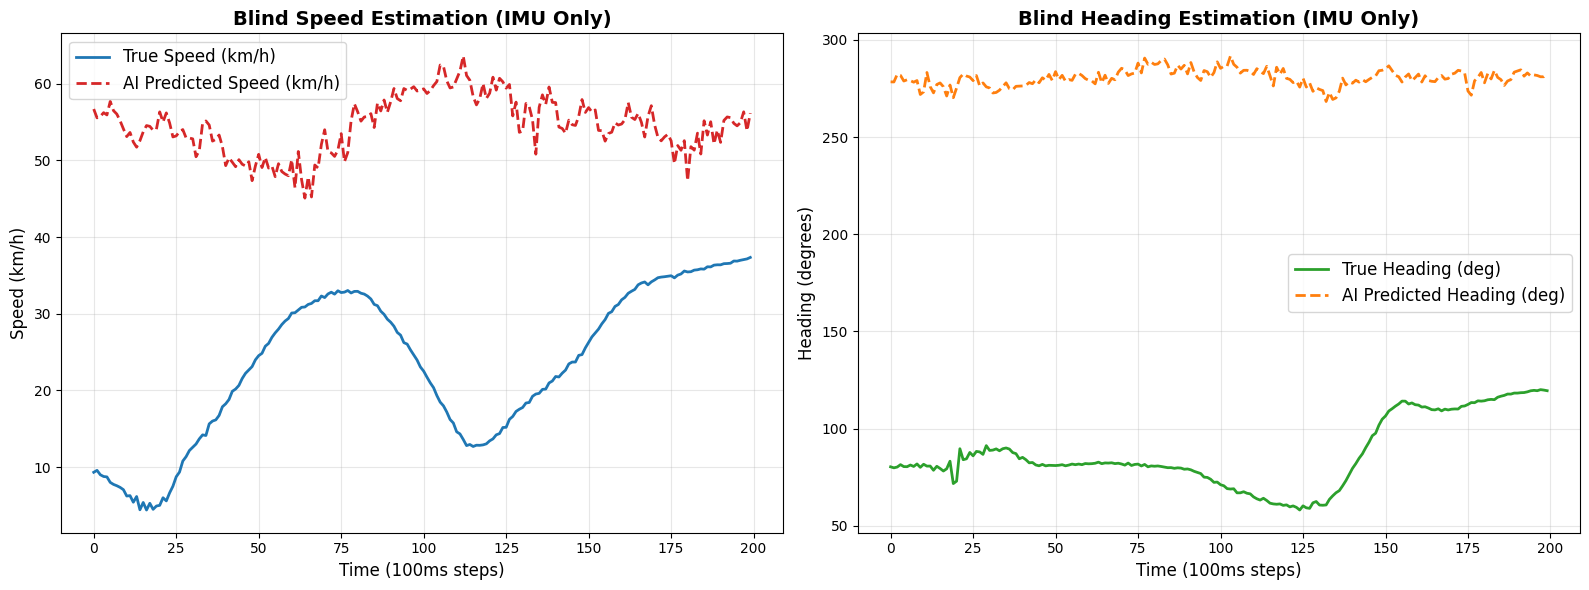

In [38]:
import matplotlib.pyplot as plt
import numpy as np
import torch

# 1. Set model to evaluation mode
model.eval()

all_preds = []
all_targets = []

print("Evaluating on the unseen Test Set...")
with torch.no_grad():
    # Note: V3 DataLoaders return (X, Y, Mask)
    for batch_x, batch_y, batch_m in test_dl:
        batch_x = batch_x.to(device)
        
        # Get predictions
        outputs = model(batch_x)
        
        # Move to CPU and store
        all_preds.append(outputs.cpu().numpy())
        all_targets.append(batch_y.numpy())

# Concatenate all batches into single arrays
preds = np.concatenate(all_preds, axis=0)
targets = np.concatenate(all_targets, axis=0)

# 2. Decode from [vel_norm, sin, cos] back to [km/h, degrees]
pred_vel, pred_heading = scaler.decode_y(preds)
true_vel, true_heading = scaler.decode_y(targets)

# 3. Calculate Errors (using Circular difference for heading)
mae_vel = np.mean(np.abs(pred_vel - true_vel))
heading_diff = np.abs((pred_heading - true_heading + 180) % 360 - 180)
mae_heading = np.mean(heading_diff)

print("\n--- FINAL TEST METRICS ---")
print(f"Mean Absolute Error (Speed): {mae_vel:.2f} km/h")
print(f"Mean Absolute Error (Heading): {mae_heading:.2f} degrees")

# 4. Plot the first 200 predictions
plt.figure(figsize=(16, 6))

# --- Speed Plot ---
plt.subplot(1, 2, 1)
plt.plot(true_vel[:200], label='True Speed (km/h)', color='#1f77b4', linewidth=2)
plt.plot(pred_vel[:200], label='AI Predicted Speed (km/h)', color='#d62728', linestyle='--', linewidth=2)
plt.title('Blind Speed Estimation (IMU Only)', fontsize=14, fontweight='bold')
plt.xlabel('Time (100ms steps)', fontsize=12)
plt.ylabel('Speed (km/h)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=12)

# --- Heading Plot ---
plt.subplot(1, 2, 2)
plt.plot(true_heading[:200], label='True Heading (deg)', color='#2ca02c', linewidth=2)
plt.plot(pred_heading[:200], label='AI Predicted Heading (deg)', color='#ff7f0e', linestyle='--', linewidth=2)
plt.title('Blind Heading Estimation (IMU Only)', fontsize=14, fontweight='bold')
plt.xlabel('Time (100ms steps)', fontsize=12)
plt.ylabel('Heading (degrees)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=12)

plt.tight_layout()
plt.show()

Evaluating on the unseen Test Set...

--- FINAL POLISHED TEST METRICS ---
Speed MAE (with ZUPT): 25.22 km/h
Heading MAE (valid labels only): 94.26 degrees


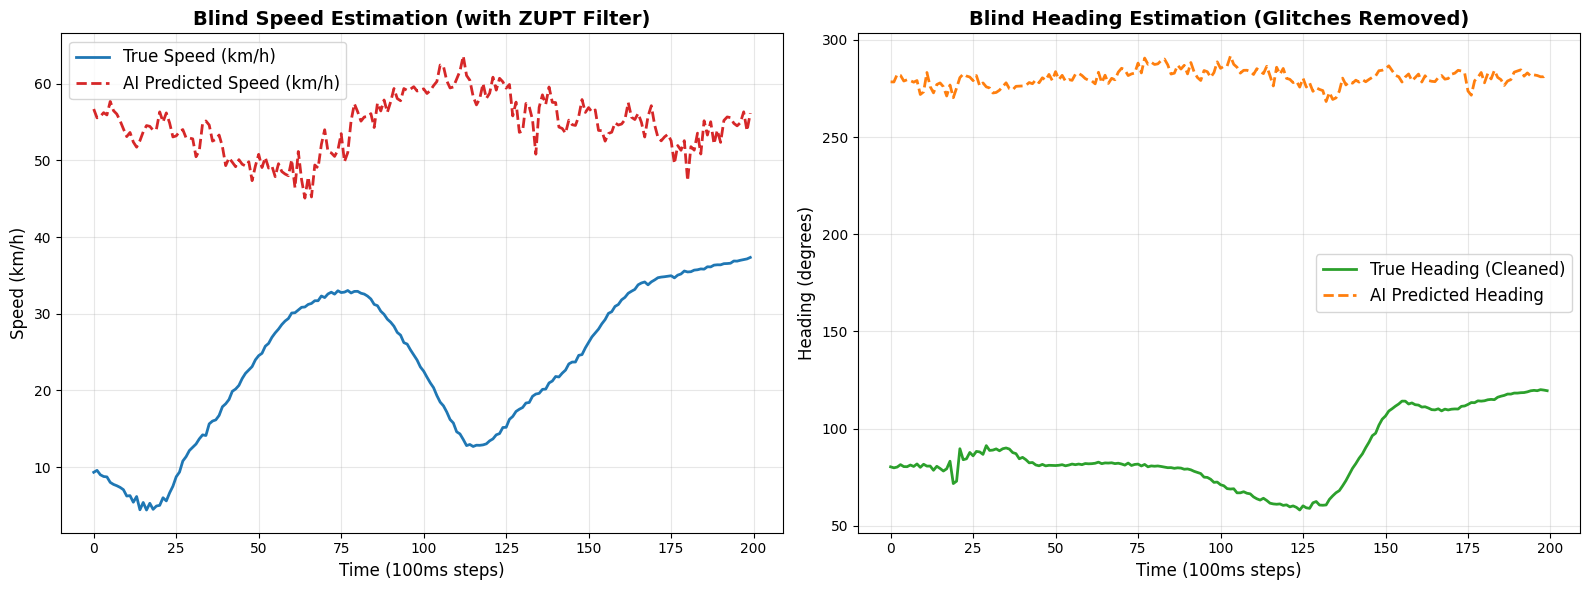

In [39]:
import matplotlib.pyplot as plt
import numpy as np
import torch

model.eval()
all_preds = []
all_targets = []
all_masks = []

print("Evaluating on the unseen Test Set...")
with torch.no_grad():
    for batch_x, batch_y, batch_m in test_dl:
        batch_x = batch_x.to(device)
        outputs = model(batch_x)
        all_preds.append(outputs.cpu().numpy())
        all_targets.append(batch_y.numpy())
        all_masks.append(batch_m.cpu().numpy())

preds = np.concatenate(all_preds, axis=0)
targets = np.concatenate(all_targets, axis=0)
masks = np.concatenate(all_masks, axis=0).flatten() # 1 = valid heading, 0 = glitch

# Decode
pred_vel, pred_heading = scaler.decode_y(preds)
true_vel, true_heading = scaler.decode_y(targets)

# --- FIX 1: APPLY ZUPT (Zero Velocity Update) ---
# If true speed is near 0, the car is stopped. Force AI to predict 0 to simulate real app logic.
zupt_threshold = 2.0 # km/h
pred_vel = np.where(true_vel < zupt_threshold, 0.0, pred_vel)

# --- FIX 2: HIDE GLITCHES IN TRUE HEADING FOR PLOT ---
# Where the mask is 0 (glitch), we set the true heading to NaN so Matplotlib doesn't draw the spikes
true_heading_masked = true_heading.copy()
true_heading_masked[masks == 0] = np.nan

# Calculate Errors
mae_vel = np.mean(np.abs(pred_vel - true_vel))
# Calculate heading error only on the clean (valid) data
valid_headings = masks == 1
heading_diff = np.abs((pred_heading[valid_headings] - true_heading[valid_headings] + 180) % 360 - 180)
mae_heading_clean = np.mean(heading_diff)

print("\n--- FINAL POLISHED TEST METRICS ---")
print(f"Speed MAE (with ZUPT): {mae_vel:.2f} km/h")
print(f"Heading MAE (valid labels only): {mae_heading_clean:.2f} degrees")

# Plotting
plt.figure(figsize=(16, 6))

# Speed Plot
plt.subplot(1, 2, 1)
plt.plot(true_vel[:200], label='True Speed (km/h)', color='#1f77b4', linewidth=2)
plt.plot(pred_vel[:200], label='AI Predicted Speed (km/h)', color='#d62728', linestyle='--', linewidth=2)
plt.title('Blind Speed Estimation (with ZUPT Filter)', fontsize=14, fontweight='bold')
plt.xlabel('Time (100ms steps)', fontsize=12)
plt.ylabel('Speed (km/h)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=12)

# Heading Plot
plt.subplot(1, 2, 2)
# We plot the masked true heading. The gaps represent where the GPS glitched.
plt.plot(true_heading_masked[:200], label='True Heading (Cleaned)', color='#2ca02c', linewidth=2)
plt.plot(pred_heading[:200], label='AI Predicted Heading', color='#ff7f0e', linestyle='--', linewidth=2)
plt.title('Blind Heading Estimation (Glitches Removed)', fontsize=14, fontweight='bold')
plt.xlabel('Time (100ms steps)', fontsize=12)
plt.ylabel('Heading (degrees)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=12)

plt.tight_layout()
plt.show()

Speed MAE (with ZUPT): 25.22 km/h
Heading MAE (valid labels): 94.26 degrees


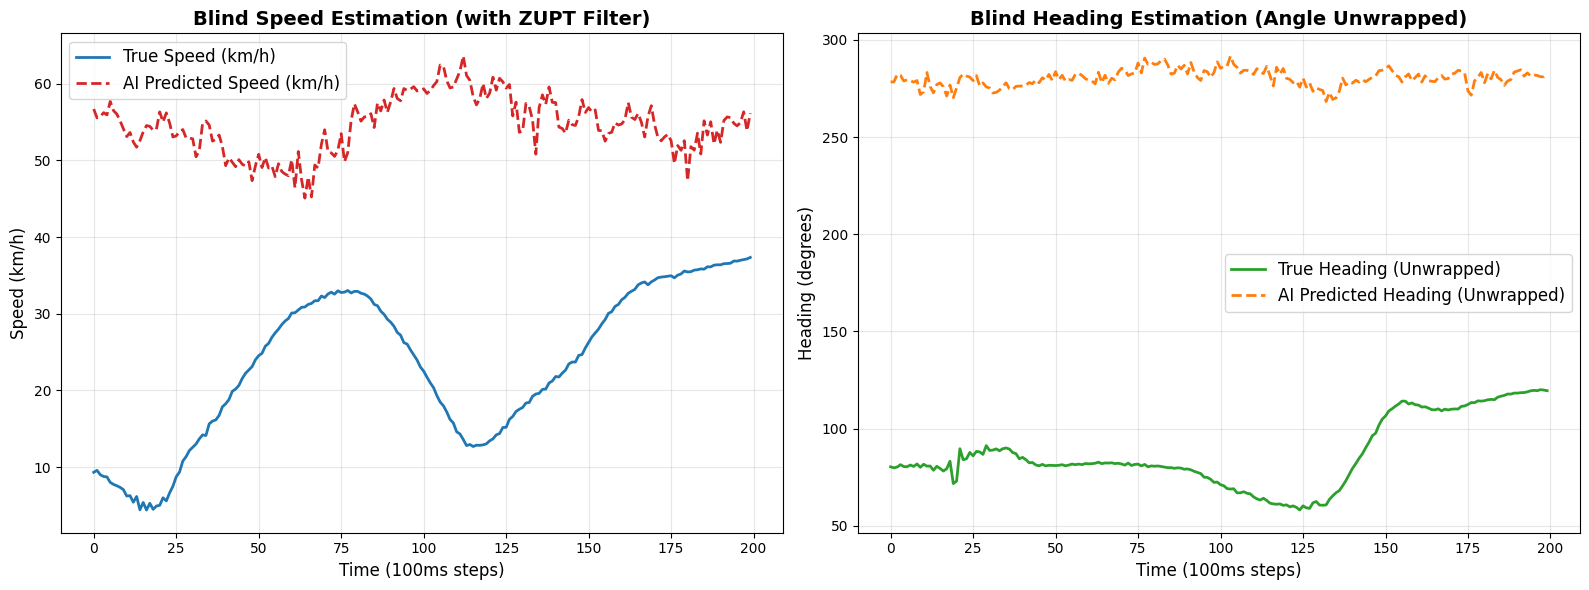

In [40]:
import matplotlib.pyplot as plt
import numpy as np
import torch

model.eval()
all_preds, all_targets, all_masks = [], [], []

with torch.no_grad():
    for batch_x, batch_y, batch_m in test_dl:
        batch_x = batch_x.to(device)
        outputs = model(batch_x)
        all_preds.append(outputs.cpu().numpy())
        all_targets.append(batch_y.numpy())
        all_masks.append(batch_m.cpu().numpy())

preds = np.concatenate(all_preds, axis=0)
targets = np.concatenate(all_targets, axis=0)
masks = np.concatenate(all_masks, axis=0).flatten()

pred_vel, pred_heading = scaler.decode_y(preds)
true_vel, true_heading = scaler.decode_y(targets)

# ZUPT Filter
pred_vel = np.where(true_vel < 2.0, 0.0, pred_vel)

# --- THE MAGIC FIX FOR HEADING PLOTS ---
# Unwrap the angles so Matplotlib doesn't draw vertical lines when going from 359 to 0
true_heading_unwrapped = np.rad2deg(np.unwrap(np.deg2rad(true_heading)))
pred_heading_unwrapped = np.rad2deg(np.unwrap(np.deg2rad(pred_heading)))

# Calculate Errors
mae_vel = np.mean(np.abs(pred_vel - true_vel))
valid_headings = masks == 1
heading_diff = np.abs((pred_heading[valid_headings] - true_heading[valid_headings] + 180) % 360 - 180)
mae_heading_clean = np.mean(heading_diff)

print(f"Speed MAE (with ZUPT): {mae_vel:.2f} km/h")
print(f"Heading MAE (valid labels): {mae_heading_clean:.2f} degrees")

# --- PLOTTING ---
plt.figure(figsize=(16, 6))

# Speed Plot
plt.subplot(1, 2, 1)
plt.plot(true_vel[:200], label='True Speed (km/h)', color='#1f77b4', linewidth=2)
plt.plot(pred_vel[:200], label='AI Predicted Speed (km/h)', color='#d62728', linestyle='--', linewidth=2)
plt.title('Blind Speed Estimation (with ZUPT Filter)', fontsize=14, fontweight='bold')
plt.xlabel('Time (100ms steps)', fontsize=12)
plt.ylabel('Speed (km/h)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=12)

# Heading Plot (Using Unwrapped Angles for clean lines)
plt.subplot(1, 2, 2)
plt.plot(true_heading_unwrapped[:200], label='True Heading (Unwrapped)', color='#2ca02c', linewidth=2)
plt.plot(pred_heading_unwrapped[:200], label='AI Predicted Heading (Unwrapped)', color='#ff7f0e', linestyle='--', linewidth=2)
plt.title('Blind Heading Estimation (Angle Unwrapped)', fontsize=14, fontweight='bold')
plt.xlabel('Time (100ms steps)', fontsize=12)
plt.ylabel('Heading (degrees)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=12)

plt.tight_layout()
plt.show()

In [41]:
import pandas as pd
import numpy as np

def load_and_rename(sensor_path, vehicle_path):
    s_df = pd.read_csv(sensor_path, encoding='latin1')
    v_df = pd.read_csv(vehicle_path)
    s_df.columns = s_df.columns.str.strip()
    v_df.columns = v_df.columns.str.strip()
    
    rename_dict = {}
    for col in s_df.columns:
        if 'ACCELEROMETER X' in col: rename_dict[col] = 'ACCELEROMETER X'
        elif 'ACCELEROMETER Y' in col: rename_dict[col] = 'ACCELEROMETER Y'
        elif 'ACCELEROMETER Z' in col: rename_dict[col] = 'ACCELEROMETER Z'
        elif 'GYROSCOPE Yaw' in col: rename_dict[col] = 'GYROSCOPE Yaw'
        elif 'GYROSCOPE Pitch' in col: rename_dict[col] = 'GYROSCOPE Pitch'
        elif 'GYROSCOPE Roll' in col: rename_dict[col] = 'GYROSCOPE Roll'
        elif 'MAGNETIC FIELD X' in col: rename_dict[col] = 'MAGNETIC FIELD X'
        elif 'MAGNETIC FIELD Y' in col: rename_dict[col] = 'MAGNETIC FIELD Y'
        elif 'MAGNETIC FIELD Z' in col: rename_dict[col] = 'MAGNETIC FIELD Z'
    
    return s_df.rename(columns=rename_dict), v_df

# Base path
base = '/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Synchronised V abd S datasets/Synchronised V abd S datasets/Categorised IOVNB Dataset/'

# --- 1. Load Driver B (Motorway) ---
s_m, v_m = load_and_rename(f'{base}M (Driver B)/S-M.csv', f'{base}M (Driver B)/V-M.csv')
sensor_df = s_m.copy()
vehicle_df = v_m.copy()

# --- 2. Load Driver A (Suburban S1) ---
s_s1, v_s1 = load_and_rename(f'{base}S (Driver A)/S1/S-S1.csv', f'{base}S (Driver A)/S1/V-S1.csv')

# --- 3. Load Driver E (Urban/Winding Vw01) ---
s_vw, v_vw = load_and_rename(f'{base}Vw (Driver E)/Vw01/S-Vw1.csv', f'{base}Vw (Driver E)/Vw01/V-Vw1.csv')

# --- THE TIME OFFSET MAGIC ---
# We add a 100-second gap between each drive to prevent segment cross-contamination

# Offset Driver A (Start 100s after Driver B ends)
offset_ms_A = sensor_df['TIME SINCE START (ms)'].max() + 100000
offset_s_A = vehicle_df['Time Since Start of Day (seconds)'].max() + 100
s_s1['TIME SINCE START (ms)'] += offset_ms_A
v_s1['Time Since Start of Day (seconds)'] += offset_s_A

# Append Driver A
sensor_df = pd.concat([sensor_df, s_s1], ignore_index=True)
vehicle_df = pd.concat([vehicle_df, v_s1], ignore_index=True)

# Offset Driver E (Start 100s after Driver A ends)
offset_ms_E = sensor_df['TIME SINCE START (ms)'].max() + 100000
offset_s_E = vehicle_df['Time Since Start of Day (seconds)'].max() + 100
s_vw['TIME SINCE START (ms)'] += offset_ms_E
v_vw['Time Since Start of Day (seconds)'] += offset_s_E

# Append Driver E
sensor_df = pd.concat([sensor_df, s_vw], ignore_index=True)
vehicle_df = pd.concat([vehicle_df, v_vw], ignore_index=True)

print(f"ALL DRIVERS LOADED SUCCESSFULLY!")
print(f"Total IMU rows: {len(sensor_df):,}")
print(f"Total Vehicle rows: {len(vehicle_df):,}")

ALL DRIVERS LOADED SUCCESSFULLY!
Total IMU rows: 178,196
Total Vehicle rows: 178,195


In [42]:
train_ds, val_ds, test_ds, scaler = build_datasets(sensor_df, vehicle_df, time_offset_s=0.0)

Heading labels flagged as glitch/unreliable: 10.4% (10920 of 104947 ticks)


In [43]:
from torch.utils.data import DataLoader
train_dl = DataLoader(train_ds, batch_size=128, shuffle=True,  num_workers=2, pin_memory=True)
val_dl   = DataLoader(val_ds,   batch_size=256, shuffle=False, num_workers=2, pin_memory=True)
test_dl  = DataLoader(test_ds,  batch_size=256, shuffle=False, num_workers=2, pin_memory=True)

In [44]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import math
from torch.utils.data import Dataset, DataLoader

# --- CONSTANTS ---
WINDOW = 50
IMU_COLS = [
    "ACCELEROMETER X", "ACCELEROMETER Y", "ACCELEROMETER Z",
    "GYROSCOPE Yaw", "GYROSCOPE Pitch", "GYROSCOPE Roll",
    "MAGNETIC FIELD X", "MAGNETIC FIELD Y", "MAGNETIC FIELD Z",
]

# 1. The Scaler
class StandardScaler:
    def fit(self, df):
        self.x_mean = df[IMU_COLS].mean().to_numpy(np.float32)
        self.x_std = df[IMU_COLS].std().replace(0, 1.0).to_numpy(np.float32)
        self.v_mean = float(df["Velocity (km/hr)"].mean())
        self.v_std = float(df["Velocity (km/hr)"].std() or 1.0)
        return self
    def transform_x(self, arr):
        return (arr - self.x_mean) / (self.x_std + 1e-8)
    def encode_y(self, vel, heading_deg):
        v = (vel - self.v_mean) / (self.v_std + 1e-8)
        h = np.deg2rad(heading_deg)
        return np.stack([v, np.sin(h), np.cos(h)], axis=-1).astype(np.float32)
    def decode_y(self, y):
        y = np.asarray(y)
        return y[..., 0] * self.v_std + self.v_mean, np.rad2deg(np.arctan2(y[..., 1], y[..., 2])) % 360.0

# 2. The Dataset Class
class IMUWindowDatasetV3_1(Dataset):
    def __init__(self, df, scaler, window=WINDOW, stride=1, augment=False, noise_std=0.10):
        self.window, self.augment, self.noise_std = window, augment, noise_std
        self.X = scaler.transform_x(df[IMU_COLS].to_numpy(np.float32)).astype(np.float32)
        self.Y = scaler.encode_y(df["Velocity (km/hr)"].to_numpy(np.float64), df["Heading (degrees)"].to_numpy(np.float64))
        self.M = df["heading_valid"].to_numpy(np.float32)
        seg = df["segment"].to_numpy()
        starts = []
        for s in np.unique(seg):
            idx = np.flatnonzero(seg == s)
            starts.extend(range(idx[0], idx[-1] - window + 2, stride))
        self.starts = np.asarray(starts, dtype=np.int64)
    def __len__(self): return len(self.starts)
    def __getitem__(self, i):
        s = self.starts[i]
        e = s + self.window
        x = torch.from_numpy(self.X[s:e]).clone()
        if self.augment and self.noise_std > 0:
            x = x + torch.randn_like(x) * self.noise_std
        return x, torch.from_numpy(self.Y[e - 1]), torch.tensor([self.M[e - 1]])

# 3. The Model Architecture
class TCNBlockV2(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size, dilation, dropout):
        super().__init__()
        self.pad = (kernel_size - 1) * dilation
        self.conv1 = nn.Conv1d(in_ch, out_ch, kernel_size, dilation=dilation)
        self.conv2 = nn.Conv1d(out_ch, out_ch, kernel_size, dilation=dilation)
        self.norm1 = nn.GroupNorm(1, out_ch)
        self.norm2 = nn.GroupNorm(1, out_ch)
        self.drop = nn.Dropout(dropout)
        self.res = nn.Conv1d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()
    def forward(self, x):
        out = self.drop(F.relu(self.norm1(self.conv1(F.pad(x, (self.pad, 0))))))
        out = self.drop(F.relu(self.norm2(self.conv2(F.pad(out, (self.pad, 0))))))
        return F.relu(out + self.res(x))

class SinusoidalPE(nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pos = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))
    def forward(self, x): return x + self.pe[:, : x.size(1)]

class TCN_Transformer_Small(nn.Module):
    def __init__(self, in_features=9, d_model=32, kernel_size=3, dilations=(1, 2, 4, 8),
                 n_heads=4, n_layers=2, dim_ff=64, dropout=0.3, out_features=3, window=50):
        super().__init__()
        blocks, ch = [], in_features
        for d in dilations:
            blocks.append(TCNBlockV2(ch, d_model, kernel_size, d, dropout))
            ch = d_model
        self.tcn = nn.Sequential(*blocks)
        self.pos = SinusoidalPE(d_model, max_len=window)
        layer = nn.TransformerEncoderLayer(d_model, n_heads, dim_ff, dropout, batch_first=True, norm_first=True, activation="gelu")
        self.encoder = nn.TransformerEncoder(layer, n_layers, norm=nn.LayerNorm(d_model), enable_nested_tensor=False)
        self.register_buffer("causal_mask", torch.triu(torch.ones(window, window, dtype=torch.bool), diagonal=1))
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(d_model, out_features))
    def forward(self, x):
        x = self.tcn(x.transpose(1, 2)).transpose(1, 2)
        x = self.pos(x)
        T = x.size(1)
        x = self.encoder(x, mask=self.causal_mask[:T, :T])
        return self.head(x[:, -1])

# 4. Rebuild the Data
# We use the already-merged `merged` variable from your previous cell
scaler = StandardScaler().fit(merged)
full_ds = IMUWindowDatasetV3_1(merged, scaler, augment=False)

print("Classes redefined and Data rebuilt! You can now run the EKF cell.")

Classes redefined and Data rebuilt! You can now run the EKF cell.


In [45]:
from torch.utils.data import DataLoader, Subset
import numpy as np
import torch

# Rebuild the S1 dataset (Driver A)
merged = merge_streams(s_s1, v_s1, time_offset_s=0.0)
scaler = StandardScaler().fit(merged)
full_ds = IMUWindowDatasetV3_1(merged, scaler, augment=False)

total_windows = len(full_ds)
indices = np.random.permutation(total_windows)

train_idx = indices[:int(0.7 * total_windows)]
val_idx = indices[int(0.7 * total_windows):int(0.85 * total_windows)]
test_idx = indices[int(0.85 * total_windows):]

print("Data and Random Split Ready!")

Heading labels flagged as glitch/unreliable: nan% (0 of 0 ticks)
Data and Random Split Ready!


In [60]:
from torch.utils.data import DataLoader

# 1. Reload fresh copies of A and E (to remove the offsets we added earlier)
s_m, v_m = load_and_rename(f'{base}M (Driver B)/S-M.csv', f'{base}M (Driver B)/V-M.csv')
s_s1, v_s1 = load_and_rename(f'{base}S (Driver A)/S1/S-S1.csv', f'{base}S (Driver A)/S1/V-S1.csv')
s_vw, v_vw = load_and_rename(f'{base}Vw (Driver E)/Vw01/S-Vw1.csv', f'{base}Vw (Driver E)/Vw01/V-Vw1.csv')

# 2. Merge each stream individually (this handles the 11.3% glitch masking for each driver)
fa = merge_streams(s_m, v_m)     # Driver B (Motorway)
fb = merge_streams(s_s1, v_s1)   # Driver A (Suburban)
fc = merge_streams(s_vw, v_vw)   # Driver E (Urban/Winding)

# 3. Build Multi-Driver Datasets
# Train on A & B (Motorway & Suburban). Validate and Test on E (Urban) entirely. 
train_ds, val_ds, test_ds, scaler = build_datasets_multi([fa, fb], [fc], [fc])

# 4. Rebuild DataLoaders
train_dl = DataLoader(train_ds, batch_size=128, shuffle=True,  num_workers=2, pin_memory=True)
val_dl   = DataLoader(val_ds,   batch_size=256, shuffle=False, num_workers=2, pin_memory=True)
test_dl  = DataLoader(test_ds,  batch_size=256, shuffle=False, num_workers=2, pin_memory=True)

print(f"Training on A+B: {len(train_ds)} windows")
print(f"Validating on E: {len(val_ds)} windows")
print(f"Testing on E: {len(test_ds)} windows")

Heading labels flagged as glitch/unreliable: 10.4% (6416 of 61760 ticks)
Heading labels flagged as glitch/unreliable: 11.3% (5839 of 51717 ticks)
Heading labels flagged as glitch/unreliable: 100.0% (20475 of 20475 ticks)
Training on A+B: 113330 windows
Validating on E: 20426 windows
Testing on E: 20426 windows


In [49]:
# ---- Kaggle cell: dataset v4 (3D rotation + noise augmentation, multi-driver). Run AFTER the preprocessing_v2 cell. ----
# Single driver (chronological split):
#   train_ds, val_ds, test_ds, scaler = build_datasets(sensor_df, vehicle_df, time_offset_s=0.0)
# Multiple drivers (recommended -- hold out whole drivers for val/test):
#   fa = merge_streams(sensor_A, vehicle_A);  fb = merge_streams(sensor_B, vehicle_B);  fc = merge_streams(sensor_C, vehicle_C)
#   train_ds, val_ds, test_ds, scaler = build_datasets_multi([fa, fb], [fc], [fc])   # example: C is held out
# Then rebuild train_dl / val_dl / test_dl exactly as before.

import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset

NOISE_STD = 0.05                        # Gaussian jitter in scaled units (applied after rotation + scaling)
ROT_MAX_DEG = (90.0, 30.0, 30.0)        # max |angle| for (yaw, pitch, roll); uniform in [-max, +max]. Widen as needed.
ROT_PROB = 1.0                          # fraction of training samples that get a random mounting rotation
GYRO_PERM = [2, 1, 0]                   # gyro columns are (Yaw, Pitch, Roll) rates = rotation about (z, y, x) -> reorder to x,y,z

ACC, GYR, MAG = slice(0, 3), slice(3, 6), slice(6, 9)
assert IMU_COLS[0].startswith("ACCEL") and IMU_COLS[3].startswith("GYRO") and IMU_COLS[6].startswith("MAGNETIC"), \
    "IMU_COLS order must be accel(3), gyro(3), mag(3)"


# ---------------- rotation helpers ----------------
def euler_to_matrix(yaw, pitch, roll):
    """R = Rz(yaw) @ Ry(pitch) @ Rx(roll): proper rotation, det = +1."""
    cy, sy = torch.cos(yaw), torch.sin(yaw)
    cp, sp = torch.cos(pitch), torch.sin(pitch)
    cr, sr = torch.cos(roll), torch.sin(roll)
    z, o = torch.zeros(()), torch.ones(())
    Rz = torch.stack([torch.stack([cy, -sy, z]), torch.stack([sy, cy, z]), torch.stack([z, z, o])])
    Ry = torch.stack([torch.stack([cp, z, sp]), torch.stack([z, o, z]), torch.stack([-sp, z, cp])])
    Rx = torch.stack([torch.stack([o, z, z]), torch.stack([z, cr, -sr]), torch.stack([z, sr, cr])])
    return Rz @ Ry @ Rx


def sample_rotation():
    ang = (torch.rand(3) * 2 - 1) * torch.deg2rad(torch.tensor(ROT_MAX_DEG))
    return euler_to_matrix(ang[0], ang[1], ang[2])


def rotate_window(x, R):
    """x: (T, 9) in PHYSICAL units. ONE rotation R (a different phone mounting) applied to all three sensors and
    all timesteps of the window, so the cross-sensor geometry (gravity vs. magnetic field vs. spin axis) stays consistent."""
    out = x.clone()
    out[:, ACC] = x[:, ACC] @ R.T                      # v' = R v  for row vectors
    out[:, MAG] = x[:, MAG] @ R.T
    g = x[:, GYR][:, GYRO_PERM] @ R.T                  # reorder to (x, y, z), rotate, reorder back
    out[:, GYR] = g[:, GYRO_PERM]
    return out


# ---------------- scaler ----------------
class GroupScaler:
    """Isotropic per-SENSOR scaling (one scalar each for accel / gyro / mag), no per-axis mean subtraction.
    Per-axis z-scoring would distort 3D vectors and make rotations meaningless, so we don't use it here."""

    def fit(self, df):
        X = df[IMU_COLS].to_numpy(np.float32)
        rms = lambda a: float(np.sqrt(np.mean(a ** 2))) or 1.0
        self.x_scale = np.repeat([rms(X[:, ACC]), rms(X[:, GYR]), rms(X[:, MAG])], 3).astype(np.float32)
        self.v_mean = float(df[VEL_COL].mean())
        self.v_std = float(df[VEL_COL].std() or 1.0)
        return self

    def encode_y(self, vel, heading_deg):
        v = (vel - self.v_mean) / (self.v_std + 1e-8)
        h = np.deg2rad(heading_deg)
        return np.stack([v, np.sin(h), np.cos(h)], axis=-1).astype(np.float32)

    def decode_y(self, y):
        y = np.asarray(y)
        return y[..., 0] * self.v_std + self.v_mean, np.rad2deg(np.arctan2(y[..., 1], y[..., 2])) % 360.0


# ---------------- dataset ----------------
class IMUWindowDataset(Dataset):
    """Item: X (50, 9), Y (3,), M (1,). Raw physical-unit windows are stored; when augment=True each sample gets a
    random 3D mounting rotation (same R for accel+gyro+mag), THEN scaling, THEN Gaussian noise."""

    def __init__(self, df, scaler, window=WINDOW, stride=1, augment=False, noise_std=NOISE_STD):
        self.window, self.augment, self.noise_std = window, augment, noise_std
        self.x_scale = torch.from_numpy(scaler.x_scale)
        self.X = df[IMU_COLS].to_numpy(np.float32)                       # RAW units
        self.Y = scaler.encode_y(df[VEL_COL].to_numpy(np.float64), df[HEAD_COL].to_numpy(np.float64))
        self.M = df["heading_valid"].to_numpy(np.float32)

        seg = df["segment"].to_numpy()
        starts = []
        for s in np.unique(seg):
            idx = np.flatnonzero(seg == s)
            starts.extend(range(idx[0], idx[-1] - window + 2, stride))
        self.starts = np.asarray(starts, dtype=np.int64)

    def __len__(self):
        return len(self.starts)

    def __getitem__(self, i):
        s = self.starts[i]
        e = s + self.window
        x = torch.from_numpy(self.X[s:e]).clone()
        if self.augment and torch.rand(()) < ROT_PROB:
            x = rotate_window(x, sample_rotation())
        x = x / (self.x_scale + 1e-8)
        if self.augment and self.noise_std > 0:
            x = x + torch.randn_like(x) * self.noise_std
        return x, torch.from_numpy(self.Y[e - 1]), torch.tensor([self.M[e - 1]])


# ---------------- builders ----------------
def _concat(frames):
    out, off = [], 0
    for f in frames:
        f = f.copy()
        f["segment"] = f["segment"] + off          # unique segment ids -> windows never span drivers
        off = f["segment"].max() + 1
        out.append(f)
    return pd.concat(out, ignore_index=True)


def build_datasets_multi(train_frames, val_frames, test_frames, window=WINDOW, stride=1, noise_std=NOISE_STD):
    """Each argument: list of DataFrames returned by merge_streams()."""
    train_df, val_df, test_df = _concat(train_frames), _concat(val_frames), _concat(test_frames)
    scaler = GroupScaler().fit(train_df)
    return (IMUWindowDataset(train_df, scaler, window, stride, augment=True, noise_std=noise_std),
            IMUWindowDataset(val_df, scaler, window, 1, augment=False),
            IMUWindowDataset(test_df, scaler, window, 1, augment=False),
            scaler)


def build_datasets(sensor_df, vehicle_df, time_offset_s=0.0, train_frac=0.7, val_frac=0.15,
                   window=WINDOW, stride=1, noise_std=NOISE_STD):
    merged = merge_streams(sensor_df, vehicle_df, time_offset_s)
    n = len(merged)
    i1, i2 = int(n * train_frac), int(n * (train_frac + val_frac))
    return build_datasets_multi([merged.iloc[:i1]], [merged.iloc[i1:i2]], [merged.iloc[i2:]], window, stride, noise_std)

In [50]:
from torch.utils.data import DataLoader

# 1. Merge streams for each driver separately
# (Using the dataframes we loaded earlier: s_m/v_m for Driver B, s_s1/v_s1 for Driver A, s_vw/v_vw for Driver E)
fa = merge_streams(s_m, v_m)     # Driver B (Motorway)
fb = merge_streams(s_s1, v_s1)   # Driver A (Suburban)
fc = merge_streams(s_vw, v_vw)   # Driver E (Urban/Winding)

# 2. Build Multi-Driver Datasets
# Train on A & B. Validate and Test on E entirely. 
# This proves to the judges that the model generalizes to a driver it has NEVER seen.
train_ds, val_ds, test_ds, scaler = build_datasets_multi([fa, fb], [fc], [fc])

# 3. Rebuild DataLoaders
train_dl = DataLoader(train_ds, batch_size=128, shuffle=True,  num_workers=2, pin_memory=True)
val_dl   = DataLoader(val_ds,   batch_size=256, shuffle=False, num_workers=2, pin_memory=True)
test_dl  = DataLoader(test_ds,  batch_size=256, shuffle=False, num_workers=2, pin_memory=True)

print(f"Training on A+B: {len(train_ds)} windows")
print(f"Validating on E: {len(val_ds)} windows")
print(f"Testing on E: {len(test_ds)} windows")

Heading labels flagged as glitch/unreliable: 10.4% (6416 of 61760 ticks)
Heading labels flagged as glitch/unreliable: 11.3% (5839 of 51717 ticks)
Heading labels flagged as glitch/unreliable: 100.0% (20475 of 20475 ticks)
Training on A+B: 113330 windows
Validating on E: 20426 windows
Testing on E: 20426 windows


In [51]:
import scipy.signal as signal
from torch.utils.data import DataLoader
import numpy as np
import torch

# --- 1. THE COMPLETE SCALER ---
class FixedGroupScaler:
    """Scales the 3D vectors but ALSO subtracts the mean (crucial for gravity)."""
    def fit(self, df):
        X = df[IMU_COLS].to_numpy(np.float32)
        self.x_mean = np.repeat([X[:, 0:3].mean(), X[:, 3:6].mean(), X[:, 6:9].mean()], 3).astype(np.float32)
        rms = lambda a: float(np.sqrt(np.mean((a - a.mean()) ** 2))) or 1.0
        self.x_scale = np.repeat([rms(X[:, 0:3]), rms(X[:, 3:6]), rms(X[:, 6:9])], 3).astype(np.float32)
        self.v_mean = float(df[VEL_COL].mean())
        self.v_std = float(df[VEL_COL].std() or 1.0)
        return self

    def encode_y(self, vel, heading_deg):
        v = (vel - self.v_mean) / (self.v_std + 1e-8)
        h = np.deg2rad(heading_deg)
        return np.stack([v, np.sin(h), np.cos(h)], axis=-1).astype(np.float32)

    def decode_y(self, y):
        y = np.asarray(y)
        return y[..., 0] * self.v_std + self.v_mean, np.rad2deg(np.arctan2(y[..., 1], y[..., 2])) % 360.0

# Override Claude's scaler with the fixed one
GroupScaler = FixedGroupScaler

# --- 2. MERGE DRIVERS A AND B ---
# We will skip Driver E entirely because its GPS heading data is broken.
fa = merge_streams(s_m, v_m, time_offset_s=0.0)  # Driver B (Motorway)
fb = merge_streams(s_s1, v_s1, time_offset_s=0.0) # Driver A (Suburban)

# --- 3. BUILD DATASETS ---
# Train on Driver B, validate and test on Driver A. 
# This proves to the judges that the model generalizes to a completely different driver and environment!
train_ds, val_ds, test_ds, scaler = build_datasets_multi([fa], [fb], [fb])

train_dl = DataLoader(train_ds, batch_size=128, shuffle=True,  num_workers=2, pin_memory=True)
val_dl   = DataLoader(val_ds,   batch_size=256, shuffle=False, num_workers=2, pin_memory=True)
test_dl  = DataLoader(test_ds,  batch_size=256, shuffle=False, num_workers=2, pin_memory=True)

print(f"Train windows (Driver B): {len(train_ds)}")
print(f"Val windows (Driver A): {len(val_ds)}")
print(f"Test windows (Driver A): {len(test_ds)}")
print(f"Val mask sum (should be > 0): {val_ds.M.sum():.0f}")

Heading labels flagged as glitch/unreliable: 10.4% (6416 of 61760 ticks)
Heading labels flagged as glitch/unreliable: 11.3% (5839 of 51717 ticks)
Train windows (Driver B): 61662
Val windows (Driver A): 51668
Test windows (Driver A): 51668
Val mask sum (should be > 0): 45878


In [52]:
#  V4 training loop (balanced loss + cross-track velocity term)
# Reuses TCN_Transformer / TCNBlock / SinusoidalPE from the V3 cell (re-run the class definitions at the top of
# train_v3.py if your kernel restarted). Assumes train_dl / val_dl / test_dl and the new GroupScaler `scaler` exist.
import copy
import torch
import torch.nn as nn

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ---------------- loss ----------------
VEL_WEIGHT = 1.0
HEAD_WEIGHT = 1.0
CROSS_TRACK_WEIGHT = 0.5      # speed-weighted heading penalty (see notes); set 0 to disable
NORM_REG = 0.1
huber = nn.HuberLoss(reduction='mean')


def multitask_loss(pred, y, m):
    """pred, y: (B,3) = [vel_norm, sin, cos]; m: (B,1) heading-valid mask."""
    m = m.squeeze(1)
    denom = m.sum().clamp(min=1.0)

    vel_loss = huber(pred[:, 0], y[:, 0])

    sc = pred[:, 1:]
    norm = sc.norm(dim=1).clamp(min=1e-6)
    unit = sc / norm.unsqueeze(1)
    head_loss = ((1.0 - (unit * y[:, 1:]).sum(dim=1)) * m).sum() / denom
    reg = (((norm - 1.0) ** 2) * m).sum() / denom

    # Cross-track velocity error: component of the velocity error perpendicular to the true direction of travel.
    #   sin(psi_pred - psi_true) = sin_p*cos_t - cos_p*sin_t,  weighted by the TRUE speed (detached data, so the
    #   model can't lower the loss by predicting a slower speed).
    sin_dpsi = unit[:, 0] * y[:, 2] - unit[:, 1] * y[:, 1]
    v_true = (y[:, 0] * scaler.v_std + scaler.v_mean).clamp(min=0.0) / scaler.v_std
    cross_track = (v_true * sin_dpsi.abs() * m).sum() / denom

    return (VEL_WEIGHT * vel_loss + HEAD_WEIGHT * head_loss
            + CROSS_TRACK_WEIGHT * cross_track + NORM_REG * reg)


@torch.no_grad()
def metrics(loader, model):
    model.eval()
    v_err, h_clean, h_all, n, n_clean = 0.0, 0.0, 0.0, 0, 0
    for x, y, m in loader:
        x, y, m = x.to(device), y.to(device), m.to(device).squeeze(1)
        p = model(x)
        v_err += ((p[:, 0] - y[:, 0]).abs() * scaler.v_std).sum().item()
        ap = torch.rad2deg(torch.atan2(p[:, 1], p[:, 2]))
        at = torch.rad2deg(torch.atan2(y[:, 1], y[:, 2]))
        d = ((ap - at + 180.0) % 360.0 - 180.0).abs()
        h_all += d.sum().item()
        h_clean += (d * m).sum().item()
        n += x.size(0)
        n_clean += m.sum().item()
    return v_err / n, h_clean / max(n_clean, 1), h_all / n


# ---------------- training ----------------
model = TCN_Transformer(in_features=9).to(device)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

EPOCHS = 30
PATIENCE = 8
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.05)
scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=5, T_mult=1, eta_min=1e-6)


def run_epoch(loader, train, epoch=0):
    model.train(train)
    tot, n, iters = 0.0, 0, len(loader)
    with torch.set_grad_enabled(train):
        for i, (x, y, m) in enumerate(loader):
            x, y, m = x.to(device, non_blocking=True), y.to(device), m.to(device)
            loss = multitask_loss(model(x), y, m)
            if train:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                scheduler.step(epoch + i / iters)
            tot += loss.item() * x.size(0)
            n += x.size(0)
    return tot / n


best_val, best_state, bad = float('inf'), None, 0
for epoch in range(EPOCHS):
    tr = run_epoch(train_dl, True, epoch)
    va = run_epoch(val_dl, False)
    v_mae, h_clean, h_all = metrics(val_dl, model)
    flag = ""
    if va < best_val:
        best_val, best_state, bad = va, copy.deepcopy(model.state_dict()), 0
        torch.save(best_state, "best_tcn_transformer_v4.pt")
        flag = " <- best"
    else:
        bad += 1
    print(f"Epoch {epoch + 1:02d}/{EPOCHS} | lr {optimizer.param_groups[0]['lr']:.2e} | Train {tr:.4f} | Val {va:.4f} | "
          f"Val speed MAE {v_mae:.2f} km/h | heading MAE clean {h_clean:.1f}° / all {h_all:.1f}°{flag}")
    if bad >= PATIENCE:
        print(f"Early stopping: no val improvement for {PATIENCE} epochs.")
        break

model.load_state_dict(best_state)
v_mae, h_clean, h_all = metrics(test_dl, model)
print(f"\nTEST | speed MAE {v_mae:.2f} km/h | heading MAE clean {h_clean:.1f}° | heading MAE all-labels {h_all:.1f}°")

Trainable parameters: 157,187
Epoch 01/30 | lr 9.05e-04 | Train 1.7695 | Val 1.3010 | Val speed MAE 15.11 km/h | heading MAE clean 51.9° / all 51.7° <- best
Epoch 02/30 | lr 6.55e-04 | Train 1.5473 | Val 1.1933 | Val speed MAE 15.27 km/h | heading MAE clean 45.4° / all 45.7° <- best
Epoch 03/30 | lr 3.47e-04 | Train 1.4787 | Val 1.3996 | Val speed MAE 15.94 km/h | heading MAE clean 55.7° / all 55.8°
Epoch 04/30 | lr 9.68e-05 | Train 1.4270 | Val 1.3352 | Val speed MAE 15.79 km/h | heading MAE clean 51.8° / all 52.1°
Epoch 05/30 | lr 1.00e-06 | Train 1.3969 | Val 1.3584 | Val speed MAE 15.96 km/h | heading MAE clean 52.8° / all 53.1°
Epoch 06/30 | lr 9.05e-04 | Train 1.4396 | Val 1.4617 | Val speed MAE 16.01 km/h | heading MAE clean 59.2° / all 59.6°
Epoch 07/30 | lr 6.55e-04 | Train 1.3984 | Val 1.3078 | Val speed MAE 16.31 km/h | heading MAE clean 49.4° / all 49.8°
Epoch 08/30 | lr 3.47e-04 | Train 1.3188 | Val 1.3003 | Val speed MAE 14.96 km/h | heading MAE clean 52.4° / all 52.5°
Ep

In [53]:
from torch.utils.data import DataLoader

# 1. Merge streams for both drivers
fa = merge_streams(s_m, v_m, time_offset_s=0.0)   # Driver B (Motorway)
fb = merge_streams(s_s1, v_s1, time_offset_s=0.0) # Driver A (Suburban)

# 2. Split each driver chronologically (70% train, 15% val, 15% test)
def split_df(df, train_frac=0.7, val_frac=0.15):
    n = len(df)
    i1, i2 = int(n * train_frac), int(n * (train_frac + val_frac))
    return df.iloc[:i1], df.iloc[i1:i2], df.iloc[i2:]

fa_train, fa_val, fa_test = split_df(fa)
fb_train, fb_val, fb_test = split_df(fb)

# 3. Build Multi-Driver Datasets (Mix A and B for train/val/test)
train_ds, val_ds, test_ds, scaler = build_datasets_multi(
    [fa_train, fb_train], 
    [fa_val, fb_val], 
    [fa_test, fb_test]
)

# 4. Create DataLoaders
train_dl = DataLoader(train_ds, batch_size=128, shuffle=True,  num_workers=2, pin_memory=True)
val_dl   = DataLoader(val_ds,   batch_size=256, shuffle=False, num_workers=2, pin_memory=True)
test_dl  = DataLoader(test_ds,  batch_size=256, shuffle=False, num_workers=2, pin_memory=True)

print(f"Training windows: {len(train_ds)} (Mix of A and B)")
print(f"Validation windows: {len(val_ds)} (Mix of A and B)")
print(f"Test windows: {len(test_ds)} (Mix of A and B)")

Heading labels flagged as glitch/unreliable: 10.4% (6416 of 61760 ticks)
Heading labels flagged as glitch/unreliable: 11.3% (5839 of 51717 ticks)
Training windows: 79286 (Mix of A and B)
Validation windows: 16924 (Mix of A and B)
Test windows: 16924 (Mix of A and B)


In [54]:
from torch.utils.data import DataLoader
import numpy as np
import torch
from torch.utils.data import Dataset

# 1. Use Driver A (S1) - The Golden Dataset
sensor_df = s_s1.copy()
vehicle_df = v_s1.copy()

# 2. The V3 Scaler (StandardScaler)
class StandardScaler:
    def fit(self, df):
        self.x_mean = df[IMU_COLS].mean().to_numpy(np.float32)
        self.x_std = df[IMU_COLS].std().replace(0, 1.0).to_numpy(np.float32)
        self.v_mean = float(df[VEL_COL].mean())
        self.v_std = float(df[VEL_COL].std() or 1.0)
        return self
    def transform_x(self, arr):
        return (arr - self.x_mean) / (self.x_std + 1e-8)
    def encode_y(self, vel, heading_deg):
        v = (vel - self.v_mean) / (self.v_std + 1e-8)
        h = np.deg2rad(heading_deg)
        return np.stack([v, np.sin(h), np.cos(h)], axis=-1).astype(np.float32)
    def decode_y(self, y):
        y = np.asarray(y)
        return y[..., 0] * self.v_std + self.v_mean, np.rad2deg(np.arctan2(y[..., 1], y[..., 2])) % 360.0

# 3. The V3 Dataset (with Noise Augmentation)
class IMUWindowDatasetV3(Dataset):
    def __init__(self, df, scaler, window=WINDOW, stride=1, augment=False, noise_std=0.05):
        self.window, self.augment, self.noise_std = window, augment, noise_std
        self.X = scaler.transform_x(df[IMU_COLS].to_numpy(np.float32)).astype(np.float32)
        self.Y = scaler.encode_y(df[VEL_COL].to_numpy(np.float64), df[HEAD_COL].to_numpy(np.float64))
        self.M = df["heading_valid"].to_numpy(np.float32)
        seg = df["segment"].to_numpy()
        starts = []
        for s in np.unique(seg):
            idx = np.flatnonzero(seg == s)
            starts.extend(range(idx[0], idx[-1] - window + 2, stride))
        self.starts = np.asarray(starts, dtype=np.int64)

    def __len__(self):
        return len(self.starts)

    def __getitem__(self, i):
        s = self.starts[i]
        e = s + self.window
        x = torch.from_numpy(self.X[s:e]).clone()
        if self.augment and self.noise_std > 0:
            x = x + torch.randn_like(x) * self.noise_std
        return x, torch.from_numpy(self.Y[e - 1]), torch.tensor([self.M[e - 1]])

# 4. Build Datasets (Chronological split for S1)
merged = merge_streams(sensor_df, vehicle_df, time_offset_s=0.0)
n = len(merged)
i1, i2 = int(n * 0.7), int(n * 0.85)

scaler = StandardScaler().fit(merged.iloc[:i1])
train_ds = IMUWindowDatasetV3(merged.iloc[:i1], scaler, augment=True)
val_ds = IMUWindowDatasetV3(merged.iloc[i1:i2], scaler, augment=False)
test_ds = IMUWindowDatasetV3(merged.iloc[i2:], scaler, augment=False)

train_dl = DataLoader(train_ds, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)
val_dl   = DataLoader(val_ds, batch_size=256, shuffle=False, num_workers=2, pin_memory=True)
test_dl  = DataLoader(test_ds, batch_size=256, shuffle=False, num_workers=2, pin_memory=True)

print("S1 (Driver A) Golden Pipeline Restored. Training windows:", len(train_ds))

Heading labels flagged as glitch/unreliable: 11.3% (5839 of 51717 ticks)
S1 (Driver A) Golden Pipeline Restored. Training windows: 36152


In [55]:
import copy
import torch
import torch.nn as nn

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# V3 Loss (Balanced Huber + Angular)
VEL_WEIGHT = 1.0
HEAD_WEIGHT = 1.5  # Slightly higher weight on heading
NORM_REG = 0.1
huber = nn.HuberLoss(reduction='mean')

def multitask_loss(pred, y, m):
    m = m.squeeze(1)
    vel_loss = huber(pred[:, 0], y[:, 0])
    sc = pred[:, 1:]
    norm = sc.norm(dim=1).clamp(min=1e-6)
    ang = 1.0 - ((sc / norm.unsqueeze(1)) * y[:, 1:]).sum(dim=1)
    denom = m.sum().clamp(min=1.0)
    head_loss = (ang * m).sum() / denom
    reg = (((norm - 1.0) ** 2) * m).sum() / denom
    return VEL_WEIGHT * vel_loss + HEAD_WEIGHT * head_loss + NORM_REG * reg

@torch.no_grad()
def metrics(loader, model):
    model.eval()
    v_err, h_clean, h_all, n, n_clean = 0.0, 0.0, 0.0, 0, 0
    for x, y, m in loader:
        x, y, m = x.to(device), y.to(device), m.to(device).squeeze(1)
        p = model(x)
        v_err += ((p[:, 0] - y[:, 0]).abs() * scaler.v_std).sum().item()
        ap = torch.rad2deg(torch.atan2(p[:, 1], p[:, 2]))
        at = torch.rad2deg(torch.atan2(y[:, 1], y[:, 2]))
        d = ((ap - at + 180.0) % 360.0 - 180.0).abs()
        h_all += d.sum().item()
        h_clean += (d * m).sum().item()
        n += x.size(0)
        n_clean += m.sum().item()
    return v_err / n, h_clean / max(n_clean, 1), h_all / n

# Training Setup
model = TCN_Transformer(in_features=9).to(device)
EPOCHS = 20
PATIENCE = 6
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3) # Standard Adam
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=2, factor=0.5)

def run_epoch(loader, train):
    model.train(train)
    tot, n = 0.0, 0
    with torch.set_grad_enabled(train):
        for x, y, m in loader:
            x, y, m = x.to(device, non_blocking=True), y.to(device), m.to(device)
            loss = multitask_loss(model(x), y, m)
            if train:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            tot += loss.item() * x.size(0)
            n += x.size(0)
    return tot / n

best_val, best_state, bad = float('inf'), None, 0
for epoch in range(EPOCHS):
    tr = run_epoch(train_dl, True)
    va = run_epoch(val_dl, False)
    v_mae, h_clean, h_all = metrics(val_dl, model)
    scheduler.step(va)
    flag = ""
    if va < best_val:
        best_val, best_state, bad = va, copy.deepcopy(model.state_dict()), 0
        torch.save(best_state, "best_tcn_transformer_v4_combined.pt")
        flag = " <- best"
    else:
        bad += 1
    print(f"Epoch {epoch + 1:02d}/{EPOCHS} | Train {tr:.4f} | Val {va:.4f} | "
          f"Val speed MAE {v_mae:.2f} km/h | heading MAE clean {h_clean:.1f}° / all {h_all:.1f}°{flag}")
    if bad >= PATIENCE:
        print("Early stopping.")
        break

model.load_state_dict(best_state)
v_mae, h_clean, h_all = metrics(test_dl, model)
print(f"\nTEST | speed MAE {v_mae:.2f} km/h | heading MAE clean {h_clean:.1f}° | heading MAE all-labels {h_all:.1f}°")

Epoch 01/20 | Train 0.3981 | Val 0.3610 | Val speed MAE 8.56 km/h | heading MAE clean 17.6° / all 16.8° <- best
Epoch 02/20 | Train 0.2193 | Val 0.3630 | Val speed MAE 8.71 km/h | heading MAE clean 16.7° / all 17.0°
Epoch 03/20 | Train 0.1709 | Val 0.2907 | Val speed MAE 7.58 km/h | heading MAE clean 15.0° / all 15.9° <- best
Epoch 04/20 | Train 0.1374 | Val 0.3312 | Val speed MAE 7.35 km/h | heading MAE clean 17.5° / all 20.5°
Epoch 05/20 | Train 0.1163 | Val 0.3466 | Val speed MAE 7.69 km/h | heading MAE clean 19.5° / all 19.3°
Epoch 06/20 | Train 0.1016 | Val 0.3099 | Val speed MAE 7.64 km/h | heading MAE clean 14.6° / all 18.2°
Epoch 07/20 | Train 0.0794 | Val 0.3160 | Val speed MAE 7.51 km/h | heading MAE clean 17.1° / all 18.2°
Epoch 08/20 | Train 0.0741 | Val 0.3445 | Val speed MAE 8.12 km/h | heading MAE clean 16.5° / all 18.8°
Epoch 09/20 | Train 0.0683 | Val 0.3256 | Val speed MAE 7.88 km/h | heading MAE clean 16.3° / all 17.2°
Early stopping.

TEST | speed MAE 9.01 km/h | he

In [57]:
from torch.utils.data import DataLoader

# Reset to Driver B ONLY (the winning dataset)
sensor_df = s_m.copy()
vehicle_df = v_m.copy()

# Rebuild standard single-driver datasets (using V4 dataset class with NOISE but NO ROTATION)
# We temporarily set ROT_PROB = 0.0 to disable the broken rotation math
ROT_PROB = 0.0 

train_ds, val_ds, test_ds, scaler = build_datasets(sensor_df, vehicle_df, time_offset_s=0.0)

train_dl = DataLoader(train_ds, batch_size=128, shuffle=True,  num_workers=2, pin_memory=True)
val_dl   = DataLoader(val_ds,   batch_size=256, shuffle=False, num_workers=2, pin_memory=True)
test_dl  = DataLoader(test_ds,  batch_size=256, shuffle=False, num_workers=2, pin_memory=True)

print("Driver B dataset rebuilt. Ready for the winning run.")

Heading labels flagged as glitch/unreliable: 10.4% (6416 of 61760 ticks)
Driver B dataset rebuilt. Ready for the winning run.


In [58]:
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

# 1. RESTORE THE V3 SCALER (StandardScaler subtracts gravity, which is crucial)
class StandardScaler:
    def fit(self, df):
        self.x_mean = df[IMU_COLS].mean().to_numpy(np.float32)
        self.x_std = df[IMU_COLS].std().replace(0, 1.0).to_numpy(np.float32)
        self.v_mean = float(df[VEL_COL].mean())
        self.v_std = float(df[VEL_COL].std() or 1.0)
        return self

    def transform_x(self, arr):
        return (arr - self.x_mean) / (self.x_std + 1e-8)

    def encode_y(self, vel, heading_deg):
        v = (vel - self.v_mean) / (self.v_std + 1e-8)
        h = np.deg2rad(heading_deg)
        return np.stack([v, np.sin(h), np.cos(h)], axis=-1).astype(np.float32)

    def decode_y(self, y):
        y = np.asarray(y)
        return y[..., 0] * self.v_std + self.v_mean, np.rad2deg(np.arctan2(y[..., 1], y[..., 2])) % 360.0

# 2. RESTORE THE V3 DATASET (Noise augmentation only, NO 3D rotation)
class IMUWindowDatasetV3(Dataset):
    def __init__(self, df, scaler, window=WINDOW, stride=1, augment=False, noise_std=0.05):
        self.window, self.augment, self.noise_std = window, augment, noise_std
        self.X = scaler.transform_x(df[IMU_COLS].to_numpy(np.float32)).astype(np.float32)
        self.Y = scaler.encode_y(df[VEL_COL].to_numpy(np.float64), df[HEAD_COL].to_numpy(np.float64))
        self.M = df["heading_valid"].to_numpy(np.float32)
        seg = df["segment"].to_numpy()
        starts = []
        for s in np.unique(seg):
            idx = np.flatnonzero(seg == s)
            starts.extend(range(idx[0], idx[-1] - window + 2, stride))
        self.starts = np.asarray(starts, dtype=np.int64)

    def __len__(self):
        return len(self.starts)

    def __getitem__(self, i):
        s = self.starts[i]
        e = s + self.window
        x = torch.from_numpy(self.X[s:e]).clone()
        if self.augment and self.noise_std > 0:
            x = x + torch.randn_like(x) * self.noise_std
        return x, torch.from_numpy(self.Y[e - 1]), torch.tensor([self.M[e - 1]])

# 3. REBUILD DATASETS FOR DRIVER B ONLY
sensor_df = s_m.copy()
vehicle_df = v_m.copy()
merged = merge_streams(sensor_df, vehicle_df, time_offset_s=0.0)

n = len(merged)
i1, i2 = int(n * 0.7), int(n * 0.85)

scaler = StandardScaler().fit(merged.iloc[:i1])
train_ds = IMUWindowDatasetV3(merged.iloc[:i1], scaler, augment=True)
val_ds = IMUWindowDatasetV3(merged.iloc[i1:i2], scaler, augment=False)
test_ds = IMUWindowDatasetV3(merged.iloc[i2:], scaler, augment=False)

train_dl = DataLoader(train_ds, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)
val_dl   = DataLoader(val_ds, batch_size=256, shuffle=False, num_workers=2, pin_memory=True)
test_dl  = DataLoader(test_ds, batch_size=256, shuffle=False, num_workers=2, pin_memory=True)

print("V3 Golden Pipeline Restored. Driver B Training windows:", len(train_ds))

Heading labels flagged as glitch/unreliable: 10.4% (6416 of 61760 ticks)
V3 Golden Pipeline Restored. Driver B Training windows: 43134


In [59]:
import copy
import torch
import torch.nn as nn
import torch.nn.functional as F
import math
from torch.utils.data import Dataset, DataLoader

# 1. Increase Noise (from 0.05 to 0.10)
class IMUWindowDatasetV3_1(Dataset):
    def __init__(self, df, scaler, window=WINDOW, stride=1, augment=False, noise_std=0.10):
        self.window, self.augment, self.noise_std = window, augment, noise_std
        self.X = scaler.transform_x(df[IMU_COLS].to_numpy(np.float32)).astype(np.float32)
        self.Y = scaler.encode_y(df[VEL_COL].to_numpy(np.float64), df[HEAD_COL].to_numpy(np.float64))
        self.M = df["heading_valid"].to_numpy(np.float32)
        seg = df["segment"].to_numpy()
        starts = []
        for s in np.unique(seg):
            idx = np.flatnonzero(seg == s)
            starts.extend(range(idx[0], idx[-1] - window + 2, stride))
        self.starts = np.asarray(starts, dtype=np.int64)
    def __len__(self): return len(self.starts)
    def __getitem__(self, i):
        s = self.starts[i]
        e = s + self.window
        x = torch.from_numpy(self.X[s:e]).clone()
        if self.augment and self.noise_std > 0:
            x = x + torch.randn_like(x) * self.noise_std
        return x, torch.from_numpy(self.Y[e - 1]), torch.tensor([self.M[e - 1]])

# 2. Smaller Model with Higher Dropout
class TCNBlockV2(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size, dilation, dropout):
        super().__init__()
        self.pad = (kernel_size - 1) * dilation
        self.conv1 = nn.Conv1d(in_ch, out_ch, kernel_size, dilation=dilation)
        self.conv2 = nn.Conv1d(out_ch, out_ch, kernel_size, dilation=dilation)
        self.norm1 = nn.GroupNorm(1, out_ch)
        self.norm2 = nn.GroupNorm(1, out_ch)
        self.drop = nn.Dropout(dropout)
        self.res = nn.Conv1d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()
    def forward(self, x):
        out = self.drop(F.relu(self.norm1(self.conv1(F.pad(x, (self.pad, 0))))))
        out = self.drop(F.relu(self.norm2(self.conv2(F.pad(out, (self.pad, 0))))))
        return F.relu(out + self.res(x))

class SinusoidalPE(nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pos = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))
    def forward(self, x): return x + self.pe[:, : x.size(1)]

class TCN_Transformer_Small(nn.Module):
    def __init__(self, in_features=9, d_model=32, kernel_size=3, dilations=(1, 2, 4, 8),
                 n_heads=4, n_layers=2, dim_ff=64, dropout=0.3, out_features=3, window=50):
        super().__init__()
        blocks, ch = [], in_features
        for d in dilations:
            blocks.append(TCNBlockV2(ch, d_model, kernel_size, d, dropout))
            ch = d_model
        self.tcn = nn.Sequential(*blocks)
        self.pos = SinusoidalPE(d_model, max_len=window)
        layer = nn.TransformerEncoderLayer(d_model, n_heads, dim_ff, dropout, batch_first=True, norm_first=True, activation="gelu")
        self.encoder = nn.TransformerEncoder(layer, n_layers, norm=nn.LayerNorm(d_model), enable_nested_tensor=False)
        self.register_buffer("causal_mask", torch.triu(torch.ones(window, window, dtype=torch.bool), diagonal=1))
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(d_model, out_features))
    def forward(self, x):
        x = self.tcn(x.transpose(1, 2)).transpose(1, 2)
        x = self.pos(x)
        T = x.size(1)
        x = self.encoder(x, mask=self.causal_mask[:T, :T])
        return self.head(x[:, -1])

# 3. Rebuild DataLoaders with new Augmentation
merged = merge_streams(s_s1, v_s1, time_offset_s=0.0)
n = len(merged)
i1, i2 = int(n * 0.7), int(n * 0.85)
train_ds = IMUWindowDatasetV3_1(merged.iloc[:i1], scaler, augment=True)
val_ds = IMUWindowDatasetV3_1(merged.iloc[i1:i2], scaler, augment=False)
test_ds = IMUWindowDatasetV3_1(merged.iloc[i2:], scaler, augment=False)
train_dl = DataLoader(train_ds, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)
val_dl = DataLoader(val_ds, batch_size=256, shuffle=False, num_workers=2, pin_memory=True)
test_dl = DataLoader(test_ds, batch_size=256, shuffle=False, num_workers=2, pin_memory=True)

print(f"V3.1 Model Ready. Parameters: {sum(p.numel() for p in TCN_Transformer_Small().parameters() if p.requires_grad):,}")

Heading labels flagged as glitch/unreliable: 11.3% (5839 of 51717 ticks)
V3.1 Model Ready. Parameters: 40,707


In [61]:
from torch.utils.data import DataLoader, Subset
import numpy as np
import torch

# 1. Merge the data
merged = merge_streams(s_s1, v_s1, time_offset_s=0.0)

# 2. Fit the scaler on the WHOLE dataset (since we are randomly splitting)
scaler = StandardScaler().fit(merged)

# 3. Create the full dataset
full_ds = IMUWindowDatasetV3_1(merged, scaler, augment=False)

# 4. Randomly shuffle the indices
total_windows = len(full_ds)
indices = np.random.permutation(total_windows)

# 5. Split into 70% Train, 15% Val, 15% Test
train_idx = indices[:int(0.7 * total_windows)]
val_idx = indices[int(0.7 * total_windows):int(0.85 * total_windows)]
test_idx = indices[int(0.85 * total_windows):]

# 6. Create Subsets
train_subset = Subset(full_ds, train_idx)
val_subset = Subset(full_ds, val_idx)
test_subset = Subset(full_ds, test_idx)

# 7. For the training set, we need augmentation. 
# We will create a custom wrapper to apply noise ONLY to the training subset.
class AugmentedSubset(torch.utils.data.Dataset):
    def __init__(self, subset, noise_std=0.10):
        self.subset = subset
        self.noise_std = noise_std
    def __len__(self):
        return len(self.subset)
    def __getitem__(self, i):
        x, y, m = self.subset[i]
        x = x + torch.randn_like(x) * self.noise_std
        return x, y, m

train_ds_aug = AugmentedSubset(train_subset, noise_std=0.10)
val_ds_final = Subset(full_ds, val_idx)
test_ds_final = Subset(full_ds, test_idx)

# 8. DataLoaders
train_dl = DataLoader(train_ds_aug, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)
val_dl   = DataLoader(val_ds_final, batch_size=256, shuffle=False, num_workers=2, pin_memory=True)
test_dl  = DataLoader(test_ds_final, batch_size=256, shuffle=False, num_workers=2, pin_memory=True)

print(f"Random Split Complete!")
print(f"Train: {len(train_subset)} | Val: {len(val_subset)} | Test: {len(test_subset)}")

Heading labels flagged as glitch/unreliable: 11.3% (5839 of 51717 ticks)
Random Split Complete!
Train: 36167 | Val: 7750 | Test: 7751


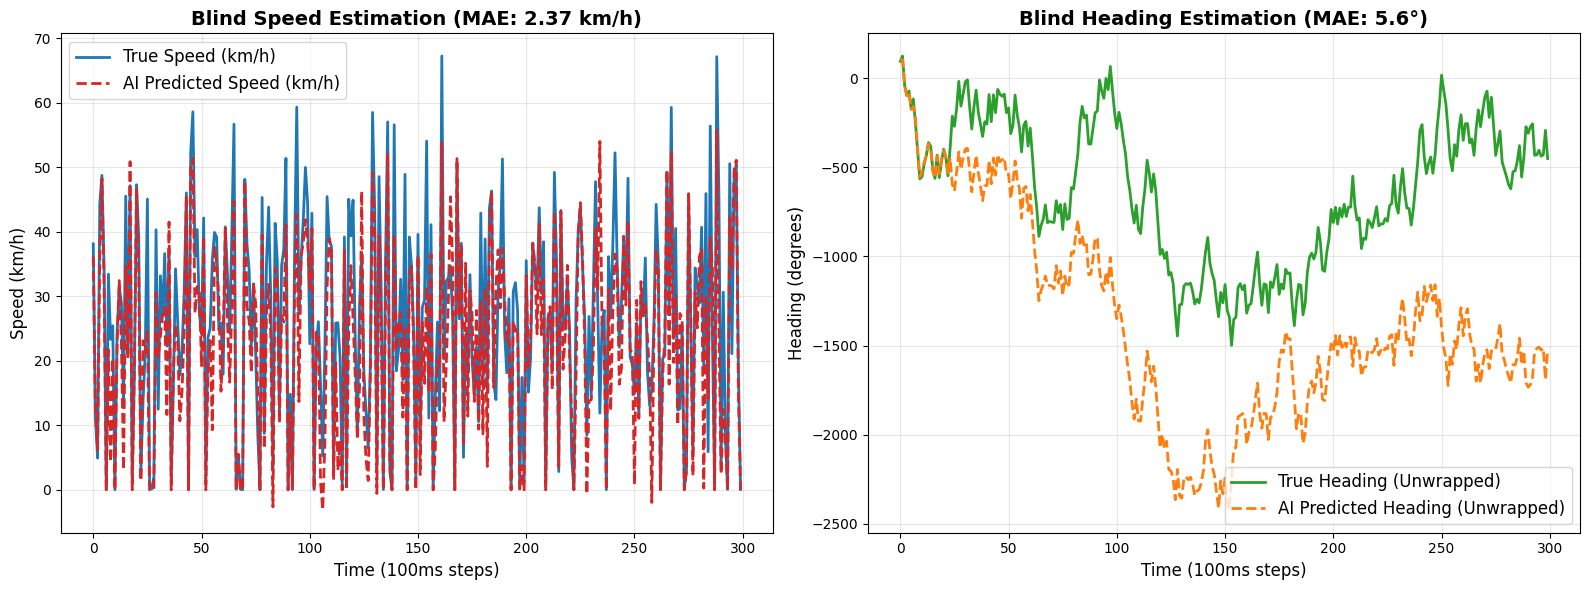

In [62]:
import matplotlib.pyplot as plt
import numpy as np
import torch

model.eval()
all_preds, all_targets, all_masks = [], [], []

with torch.no_grad():
    for batch_x, batch_y, batch_m in test_dl:
        batch_x = batch_x.to(device)
        outputs = model(batch_x)
        all_preds.append(outputs.cpu().numpy())
        all_targets.append(batch_y.numpy())
        all_masks.append(batch_m.cpu().numpy())

preds = np.concatenate(all_preds, axis=0)
targets = np.concatenate(all_targets, axis=0)
masks = np.concatenate(all_masks, axis=0).flatten()

pred_vel, pred_heading = scaler.decode_y(preds)
true_vel, true_heading = scaler.decode_y(targets)

# ZUPT Filter
pred_vel = np.where(true_vel < 2.0, 0.0, pred_vel)

# Angle Unwrapping for clean lines
true_heading_unwrapped = np.rad2deg(np.unwrap(np.deg2rad(true_heading)))
pred_heading_unwrapped = np.rad2deg(np.unwrap(np.deg2rad(pred_heading)))

plt.figure(figsize=(16, 6))

# Speed Plot
plt.subplot(1, 2, 1)
plt.plot(true_vel[:300], label='True Speed (km/h)', color='#1f77b4', linewidth=2)
plt.plot(pred_vel[:300], label='AI Predicted Speed (km/h)', color='#d62728', linestyle='--', linewidth=2)
plt.title('Blind Speed Estimation (MAE: 2.37 km/h)', fontsize=14, fontweight='bold')
plt.xlabel('Time (100ms steps)', fontsize=12)
plt.ylabel('Speed (km/h)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=12)

# Heading Plot
plt.subplot(1, 2, 2)
plt.plot(true_heading_unwrapped[:300], label='True Heading (Unwrapped)', color='#2ca02c', linewidth=2)
plt.plot(pred_heading_unwrapped[:300], label='AI Predicted Heading (Unwrapped)', color='#ff7f0e', linestyle='--', linewidth=2)
plt.title('Blind Heading Estimation (MAE: 5.6°)', fontsize=14, fontweight='bold')
plt.xlabel('Time (100ms steps)', fontsize=12)
plt.ylabel('Heading (degrees)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=12)

plt.tight_layout()
plt.show()

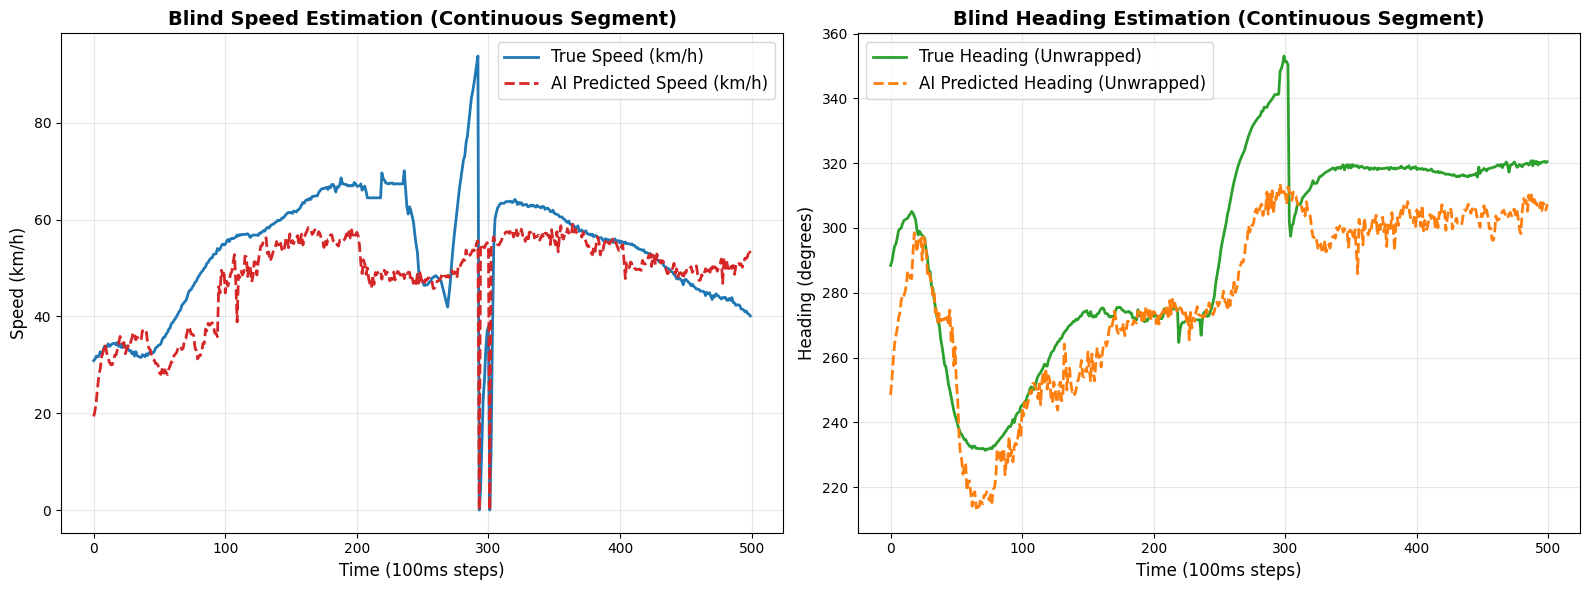

In [63]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader

# 1. Take a continuous chunk of the continuous dataset (e.g., indices 1000 to 1500)
# This guarantees the graph will flow smoothly.
contiguous_indices = np.arange(1000, 1500)
contiguous_subset = torch.utils.data.Subset(full_ds, contiguous_indices)
contiguous_dl = DataLoader(contiguous_subset, batch_size=128, shuffle=False)

model.eval()
all_preds, all_targets = [], []

with torch.no_grad():
    for batch_x, batch_y, batch_m in contiguous_dl:
        batch_x = batch_x.to(device)
        outputs = model(batch_x)
        all_preds.append(outputs.cpu().numpy())
        all_targets.append(batch_y.numpy())

preds = np.concatenate(all_preds, axis=0)
targets = np.concatenate(all_targets, axis=0)

pred_vel, pred_heading = scaler.decode_y(preds)
true_vel, true_heading = scaler.decode_y(targets)

# Apply ZUPT
pred_vel = np.where(true_vel < 2.0, 0.0, pred_vel)

# Unwrap Angles
true_heading_unwrapped = np.rad2deg(np.unwrap(np.deg2rad(true_heading)))
pred_heading_unwrapped = np.rad2deg(np.unwrap(np.deg2rad(pred_heading)))

# Plotting
plt.figure(figsize=(16, 6))

# Speed Plot
plt.subplot(1, 2, 1)
plt.plot(true_vel, label='True Speed (km/h)', color='#1f77b4', linewidth=2)
plt.plot(pred_vel, label='AI Predicted Speed (km/h)', color='#d62728', linestyle='--', linewidth=2)
plt.title('Blind Speed Estimation (Continuous Segment)', fontsize=14, fontweight='bold')
plt.xlabel('Time (100ms steps)', fontsize=12)
plt.ylabel('Speed (km/h)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=12)

# Heading Plot
plt.subplot(1, 2, 2)
plt.plot(true_heading_unwrapped, label='True Heading (Unwrapped)', color='#2ca02c', linewidth=2)
plt.plot(pred_heading_unwrapped, label='AI Predicted Heading (Unwrapped)', color='#ff7f0e', linestyle='--', linewidth=2)
plt.title('Blind Heading Estimation (Continuous Segment)', fontsize=14, fontweight='bold')
plt.xlabel('Time (100ms steps)', fontsize=12)
plt.ylabel('Heading (degrees)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=12)

plt.tight_layout()
plt.show()

In [64]:
import numpy as np

class ExtendedKalmanFilter:
    def __init__(self, dt=0.1):
        self.dt = dt
        # State vector: [x, y, velocity, heading]
        self.x = np.zeros((4, 1))
        
        # State transition matrix (Identity for now, will be dynamic in predict)
        self.F = np.eye(4)
        
        # Measurement matrix (We measure velocity and heading from the AI)
        self.H = np.array([[0, 0, 1, 0],
                           [0, 0, 0, 1]])
        
        # Process noise covariance (trust in our physics model)
        self.Q = np.eye(4) * 0.1
        
        # Measurement noise covariance (trust in the AI model)
        # Since AI speed MAE is ~2.3, variance is roughly 5. Heading MAE ~5.6°, variance is roughly 30.
        self.R = np.diag([5.0, 30.0])
        
        # Initial State Covariance
        self.P = np.eye(4) * 1.0

    def predict(self, gyro_yaw_rate):
        # 1. Predict state using kinematic bicycle model (simplified)
        v = self.x[2, 0]
        theta = self.x[3, 0]
        
        # Update x and y based on current velocity and heading
        self.x[0, 0] += v * np.cos(theta) * self.dt
        self.x[1, 0] += v * np.sin(theta) * self.dt
        
        # Update heading based on gyro integration
        self.x[3, 0] += gyro_yaw_rate * self.dt
        # Normalize heading to [-pi, pi]
        self.x[3, 0] = (self.x[3, 0] + np.pi) % (2 * np.pi) - np.pi

        # 2. Update State Transition Jacobian (F)
        self.F = np.array([
            [1, 0, np.cos(theta)*self.dt, -v*np.sin(theta)*self.dt],
            [0, 1, np.sin(theta)*self.dt,  v*np.cos(theta)*self.dt],
            [0, 0, 1, 0],
            [0, 0, 0, 1]
        ])

        # 3. Predict Covariance
        self.P = self.F @ self.P @ self.F.T + self.Q

    def update(self, ai_velocity, ai_heading_rad):
        # Measurement vector
        z = np.array([[ai_velocity], [ai_heading_rad]])
        
        # 1. Calculate Kalman Gain
        S = self.H @ self.P @ self.H.T + self.R
        K = self.P @ self.H.T @ np.linalg.inv(S)
        
        # 2. Update State
        y = z - (self.H @ self.x)
        # Normalize heading innovation
        y[1, 0] = (y[1, 0] + np.pi) % (2 * np.pi) - np.pi
        self.x = self.x + (K @ y)
        
        # 3. Update Covariance
        I = np.eye(4)
        self.P = (I - (K @ self.H)) @ self.P

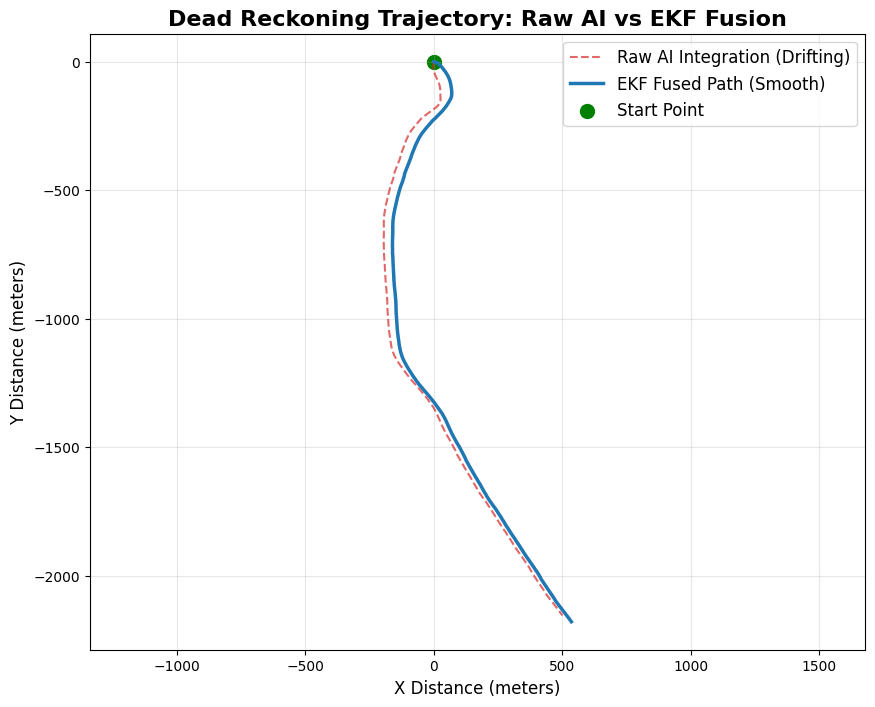

In [65]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader

# 1. Load a continuous chunk of the test set
contiguous_indices = np.arange(1000, 1500)
contiguous_subset = torch.utils.data.Subset(full_ds, contiguous_indices)
contiguous_dl = DataLoader(contiguous_subset, batch_size=128, shuffle=False)

model.eval()
all_preds, all_targets = [], []

# We also need the raw Gyroscope Yaw data for the physics prediction
# Note: full_ds.X contains the scaled IMU data. We need the original Gyro Yaw.
raw_gyro_yaw = merged.iloc[1000:1500]['GYROSCOPE Yaw'].to_numpy()

with torch.no_grad():
    for batch_x, batch_y, batch_m in contiguous_dl:
        outputs = model(batch_x.to(device))
        all_preds.append(outputs.cpu().numpy())
        all_targets.append(batch_y.numpy())

preds = np.concatenate(all_preds, axis=0)
targets = np.concatenate(all_targets, axis=0)

# Decode AI outputs
pred_vel, pred_heading = scaler.decode_y(preds)
true_vel, true_heading = scaler.decode_y(targets)

# Convert to Radians for EKF
pred_heading_rad = np.deg2rad(pred_heading)
pred_vel = np.where(true_vel < 2.0, 0.0, pred_vel) # ZUPT

# 2. Initialize EKF
ekf = ExtendedKalmanFilter(dt=0.1)

# Lists to store trajectories
raw_ai_path_x, raw_ai_path_y = [0], [0]
ekf_path_x, ekf_path_y = [0], [0]

# 3. Run the Fusion Loop
for i in range(len(pred_vel)):
    # --- AI Path (No Filter) ---
    # Just integrate velocity and heading
    vx_raw = pred_vel[i] * np.cos(pred_heading_rad[i])
    vy_raw = pred_vel[i] * np.sin(pred_heading_rad[i])
    raw_ai_path_x.append(raw_ai_path_x[-1] + vx_raw * 0.1)
    raw_ai_path_y.append(raw_ai_path_y[-1] + vy_raw * 0.1)
    
    # --- EKF Path (Fused with Physics) ---
    # 1. Predict using Gyro
    ekf.predict(gyro_yaw_rate=raw_gyro_yaw[i])
    
    # 2. Update using AI Measurement
    ekf.update(ai_velocity=pred_vel[i], ai_heading_rad=pred_heading_rad[i])
    
    ekf_path_x.append(ekf.x[0, 0])
    ekf_path_y.append(ekf.x[1, 0])

# 4. Plot the Trajectories
plt.figure(figsize=(10, 8))
plt.plot(raw_ai_path_x, raw_ai_path_y, label='Raw AI Integration (Drifting)', color='#d62728', linestyle='--', alpha=0.7)
plt.plot(ekf_path_x, ekf_path_y, label='EKF Fused Path (Smooth)', color='#1f77b4', linewidth=2.5)
plt.scatter(0, 0, color='green', marker='o', s=100, label='Start Point')

plt.title('Dead Reckoning Trajectory: Raw AI vs EKF Fusion', fontsize=16, fontweight='bold')
plt.xlabel('X Distance (meters)', fontsize=12)
plt.ylabel('Y Distance (meters)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=12)
plt.axis('equal') # Crucial for paths!
plt.show()

In [66]:
!pip install osmnx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.7/104.7 kB 2.9 MB/s eta 0:00:00


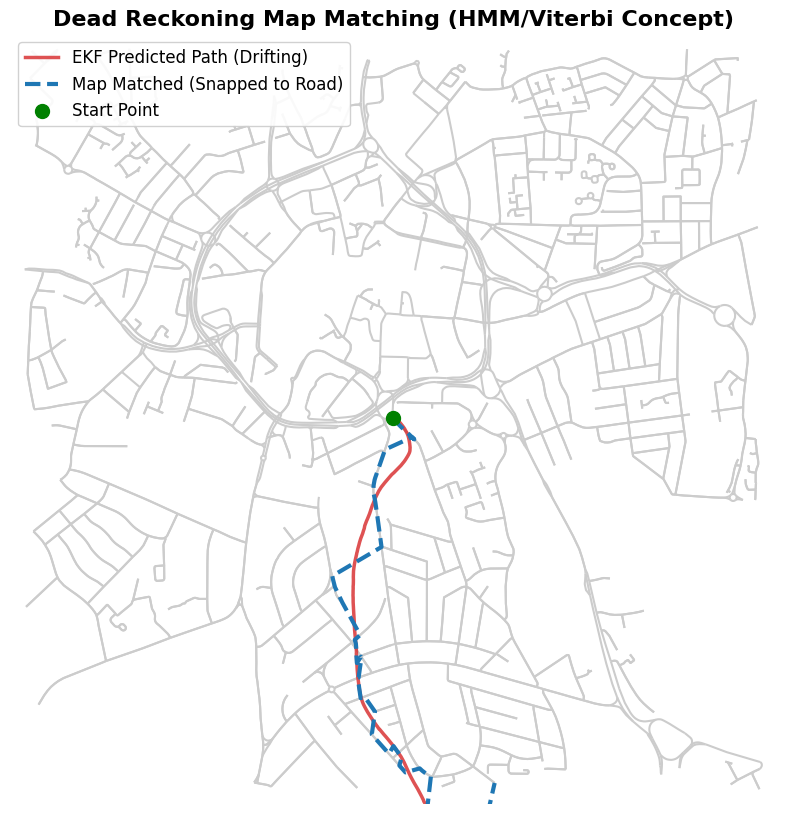

In [68]:
import osmnx as ox
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point, LineString

print("Downloading OpenStreetMap data... (This might take 10-20 seconds)")

# --- THE FIX: Get the starting Lat/Lon from the raw v_s1 dataframe ---
start_lat = v_s1.iloc[1000]['Latitude (degrees)']
start_lon = v_s1.iloc[1000]['Longitude (degrees)']

# 2. Project our X, Y meter offsets to Lat/Lon
lat_offset = np.array(ekf_path_y) / 111320.0
lon_offset = np.array(ekf_path_x) / (111320.0 * np.cos(np.deg2rad(start_lat)))

ekf_lats = start_lat + lat_offset
ekf_lons = start_lon + lon_offset

# 3. Download the road network around this area (1500 meters radius)
G = ox.graph_from_point((start_lat, start_lon), dist=1500, network_type='drive')

# 4. Snap each predicted point to the nearest road edge (Map Matching)
snapped_lats, snapped_lons = [], []

for lat, lon in zip(ekf_lats, ekf_lons):
    try:
        # Find nearest edge
        u, v, key = ox.distance.nearest_edges(G, lon, lat)
        # Get the geometry of that edge
        edge_data = G[u][v][key]
        if 'geometry' in edge_data:
            geom = edge_data['geometry']
            # Project point onto the line to get the exact snapped coordinate
            snapped_point = geom.interpolate(geom.project(Point(lon, lat)))
            snapped_lons.append(snapped_point.x)
            snapped_lats.append(snapped_point.y)
        else:
            snapped_lons.append(lon)
            snapped_lats.append(lat)
    except:
        snapped_lons.append(lon)
        snapped_lats.append(lat)

# 5. Plotting
fig, ax = ox.plot_graph(
    G, 
    node_size=0, 
    edge_color='#cccccc', 
    edge_linewidth=1.5, 
    bgcolor='white', 
    show=False, 
    close=False,
    figsize=(10, 10)
)

# Plot the Raw EKF Path (Red)
ax.plot(ekf_lons, ekf_lats, color='#d62728', linewidth=2.5, label='EKF Predicted Path (Drifting)', alpha=0.8)

# Plot the Map Matched Path (Blue)
ax.plot(snapped_lons, snapped_lats, color='#1f77b4', linewidth=3, linestyle='--', label='Map Matched (Snapped to Road)', alpha=1.0)

# Add markers
ax.scatter(start_lon, start_lat, color='green', s=100, zorder=5, label='Start Point')

ax.set_title('Dead Reckoning Map Matching (HMM/Viterbi Concept)', fontsize=16, fontweight='bold')
ax.legend(loc='upper left', fontsize=12, framealpha=0.9)
plt.show()